<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/QNN_ByzantineFederated_Xia2021.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum neural network federated learning under Byzantine attacks: Xia, Tao and Li (2021) step by step

This notebook re-implements, runs and checks the experiments of

> Qi Xia, Zeyi Tao and Qun Li,
> "Defending Against Byzantine Attacks in Quantum Federated Learning",
> *17th International Conference on Mobility, Sensing and Networking (MSN)* 2021, pp. 145-152, DOI [10.1109/MSN53354.2021.00035](https://doi.org/10.1109/MSN53354.2021.00035).

**What the notebook does.** Several simulated *quantum machines* (nodes) each hold a few pairs of quantum states and jointly train one small
**deep quantum neural network** (DQNN, widths 2-3-2 qubits) so that it learns a hidden unitary `Ug`. Training follows the **QuantumFed** framework: every node computes
an *update unitary* and the server applies the received unitaries one after the other. 30 % of the nodes are **Byzantine**: instead of their honest update unitary they upload a
random unitary. The notebook (i) rebuilds the paper's data and the DQNN training rule of Beer et al., with an exact NumPy density-matrix simulator that is **asserted equal to the real Qiskit circuit**,
(ii) re-implements the paper's three defences, the quantum versions of **FABA**, **Krum** and **ToFi**, (iii) re-draws the paper's Fig. 3 (all nodes take part, N = 10) and Fig. 4 (10 of 100 nodes
selected per round) in a Byzantine and in a clean environment, and (iv) adds what the paper lacks: several seeds, **classical twins** of the model trained under exactly the same federated / Byzantine protocol,
a **rule-aware (adaptive) attacker** as a control for the "the defence works" claim, and a claim-by-claim verdict table.

**How to run.** Open in Google Colab (a CPU runtime is enough; no GPU, no quantum hardware, no API key, no download: the data is generated as in the paper), then *Runtime -> Run all*.
With `FAST_MODE = True` (1 seed, 40 rounds) the notebook takes about 10 minutes; with `FAST_MODE = False` (2 seeds, 80 rounds) about an hour and a half on a laptop CPU.

**What you get at the end.** The re-drawn Fig. 3 and Fig. 4, a table of final fidelity / MSE / speed / leaked Byzantine updates for every rule, the same for the classical twins, the adaptive-attack control,
and a table that gives a verdict ("reproduced" / "not reached" / "cannot be checked") for every checkable statement of the paper.

## The paper in one page

**Problem.** In *quantum federated learning* several quantum machines keep their own (quantum) training data and cooperate to train one global model. As in classical federated learning, a
**Byzantine** node can upload anything instead of its honest result. In QuantumFed the uploaded object is not a gradient but an **update unitary**, so the classical defences (which compute distances and means of
tensors) must be re-defined for unitaries.

**Model (Sec. II-B, Fig. 1).** A feed-forward DQNN with layer widths `[2, 3, 2]`. Layer `l` applies the perceptron unitaries `U_{l,1} ... U_{l,m_l}` (each acts on the `m_{l-1}` qubits of the previous layer and one fresh qubit of layer `l`)
and then traces the previous layer out (Eq. 1-2). Training (Beer et al. 2020): each perceptron unitary is moved by `exp(i eps K)`, with the update matrix `K` computed from forward and backward propagated states.
The cost is the **fidelity** `C = mean <phi_out| rho_out |phi_out>` (optimum 1); a second metric is the **MSE** of Eq. 9.

**QuantumFed (Sec. II-C).** `QuanFedNode` derives its update unitaries on its local (non-iid) data, `QuanFedServer` applies the received unitaries successively to the global model.

**Byzantine model (Def. 1, Sec. IV-A).** A Byzantine node sends `U_a != U_i`; in the experiments `U_a` comes from a Gaussian random Hermitian matrix turned into a unitary; 30 % of the nodes are Byzantine.

**Defences (Sec. III).** *FABA* (distance based): repeatedly remove the update farthest from the element-wise mean. *Krum* (score based): keep only the update with the smallest sum of distances to its `Np - f - 2` nearest neighbours.
*ToFi* (reference-data based): evaluate every candidate model on a small clean reference set, normalise the losses and keep the update unitaries with a high enough normalised fidelity. The distance is the element-wise matrix Euclidean distance (Eq. 4).
Median rules are not transferred (Sec. III-E).

**Data (Sec. IV-A).** Synthetic: a random global unitary `Ug`, random input states, outputs `Ug|in>`; a proportion of the training pairs is polluted with random input/output pairs; the pairs are sorted and cut into blocks to make the nodes non-iid;
the test pairs are clean and held by the server. Simulated with QuTiP. `eta = 1.0`, `eps = 0.1`.

**Protocol and claims.** (1) *All nodes participate* (N = 10, Np = 10, 3 Byzantine; Fig. 3): FABA and ToFi defend, FABA is a little faster, Krum shows a trend to defend but is far too slow; in a clean environment FABA converges faster than ToFi and Krum is worst.
(2) *Selected nodes* (N = 100, Np = 10, 30 Byzantine; Fig. 4): only ToFi defends, FABA only somehow defends and is unstable, Krum is as bad as doing nothing; the clean environment behaves like the all-node case.
(3) Abstract: "a similar performance of the quantum version with the classic version". The paper gives **no numbers**, only curves.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Simulator | QuTiP | exact NumPy density-matrix simulator of the same DQNN (vectorised over samples); **asserted equal** to a real Qiskit 7-qubit circuit (see the circuit section below) |
| Network, `eta`, `eps` | `[2,3,2]`, `eta = 1.0`, `eps = 0.1` | same |
| Training update | derived "similar to backpropagation" in Beer et al. | Beer et al.'s update matrix `K = i eta 2^(m_(l-1)) / N * sum tr_rest [A, B]`, **checked against a finite-difference gradient** (Section 1) |
| Data | random `Ug`, random inputs, outputs `Ug|in>`, some polluted pairs | same; Haar-random `Ug` and inputs; **polluted share 10 %** (`# CHOICE:` not stated) |
| Pairs per node, test pairs, reference pairs | not stated | 4 per node (40 pairs for N = 10, 400 for N = 100), 20 test, 10 reference (`# CHOICE:`) |
| Non-iid split | sort "by vector representation value", divide in order | sort by the modulus of the first input amplitude, consecutive blocks (`# CHOICE:`) |
| Rounds | not stated (curves only) | 80 (full) / 40 (FAST_MODE) (`# CHOICE:`) |
| Local work and server step | one update unitary per node; server applies the received unitaries successively | one step per round; `K` of a node is normalised by the data of all *selected* nodes, so the product of all honest update unitaries equals one pooled Beer step; a rule that keeps fewer nodes therefore takes a smaller step (`# CHOICE:`) |
| Byzantine update | Gaussian Hermitian -> unitary | `exp(i H)`, `H = (G + G^dagger)/2`, `G` complex standard normal, one random unitary per perceptron |
| Distance (Eq. 4) | element-wise Euclidean, printed with real squares | `sqrt(sum |u1 - u2|^2)` on the **concatenation of all update unitaries of a node** (`# CHOICE:` node-level decision) |
| Mean (Eq. 5) | element-wise mean (not unitary) | same |
| FABA loop | Algorithm 1 starts at `k = 1` and loops while `k < alpha Np` | removes `ceil(alpha Np)` updates (3 of 10); the printed version, which removes one fewer, is run as an ablation (`faba_literal`) (`# CHOICE:`) |
| `alpha` for FABA / Krum | "assumed proportion" | 0.3, the true value (`# CHOICE:`) |
| Krum | `f = ceil(alpha Np)`, `Np - f - 2` neighbours | same |
| ToFi | loss filter `exp(-L_i) < tau`, `tau` not given; a "similarity filter" is mentioned but is not in Algorithm 3 | loss filter only; `tau` picked from {1.0, 1.2, 1.6, 2.0} ({1.2, 2.0} in FAST_MODE) on a validation seed (`# CHOICE:`) |
| ToFi candidate model | `f(U_Ri U, xi_R)` | the node's update unitaries applied to every perceptron of the global model, evaluated on the reference pairs |
| MSE (Eq. 9) | `||rho_out - |phi><phi| ||^2` | squared Frobenius norm, averaged over the test pairs |
| Seeds | not stated | 1 (FAST) / 2 (full); every seed has its own `Ug`, data, initial model and Byzantine nodes |
| Classical comparison | the abstract claims similar behaviour to the classic version; no classical experiment | classical **linear** and **MLP-16** twins, same data, nodes, schedule, attack and rules (Euclidean distance on parameter updates) |
| Adaptive attacker | not studied (the paper says the study is at an early stage) | added as a control, not scored as a paper claim |

## 0. Setup

The simulator needs only NumPy / SciPy / pandas / matplotlib (pre-installed on Colab). Qiskit is installed (pinned to the tested version) to draw the circuit and to verify the simulator. Nothing is downloaded: the paper's data is
synthetic and is generated in Section 2.

In [1]:
import sys, importlib
IN_COLAB = "google.colab" in sys.modules

def _have(m):
    try:
        importlib.import_module(m)
        return True
    except Exception:
        return False

# The simulator itself needs only numpy / scipy / matplotlib / pandas (all pre-installed on Colab).
# Qiskit is used for the circuit drawing and to CHECK the simulator against a real circuit.
# Pinned to the versions this notebook was tested with; guarded so a local environment is not touched.
if IN_COLAB or not _have("qiskit"):
    !pip -q install "qiskit==2.5.2" pylatexenc
    print("Qiskit installed. If Colab asks for a restart, restart the runtime and run all cells again.")
else:
    import qiskit
    print("qiskit already available:", qiskit.__version__)


qiskit already available: 2.5.2


In [2]:
SEED = 42
FAST_MODE = False           # True: class demo (1 seed, 40 rounds, about 10 minutes on an idle CPU); False: full budget (2 seeds, 80 rounds, about 1.3 hours)
IBM_TOKEN = ""              # not used: the paper's experiment is a classical simulation of the quantum network (no hardware)

# ---- the quantum network and the QuantumFed hyper-parameters (paper Sec. IV-A) ----------------------------------------
ARCH = [2, 3, 2]            # paper: "[2, 3, 2] quantum neural network"  (2 input, 3 hidden, 2 output qubits)
ETA, EPS = 1.0, 0.1         # paper: eta = 1.0, epsilon = 0.1
BYZ_FRAC = 0.30             # paper: 30 % of the nodes are Byzantine
SCENARIOS = {"all": (10, 10),    # (N, Np) = (10, 10): all nodes take part in every round (paper Sec. IV-B, Fig. 3)
             "sel": (100, 10)}   # (N, Np) = (100, 10): 10 randomly selected nodes per round, 30 of 100 Byzantine (Sec. IV-C, Fig. 4)

# ---- choices the paper does not state (see the "What had to be chosen" table) -----------------------------------------
PAIRS_PER_NODE = 4          # CHOICE: training pairs (|phi_in>, Ug|phi_in>) held by every node
NOISY_FRAC = 0.10           # CHOICE: share of training pairs replaced by random (input, output) pairs ("polluted" data)
N_TEST, N_REF = 20, 10      # CHOICE: server-side clean test pairs / ToFi reference pairs
ALPHA = 0.30                # assumed Byzantine proportion handed to FABA and Krum (= the true proportion)
# CHOICE: ToFi filter threshold tau (not given in the paper), picked from TAU_GRID on a validation seed (Section 3b)
ADAPT_GRID = [0, 0.1, 0.25, 0.5, 1, 2, 4, 8]   # step sizes tried by the rule-aware (adaptive) attacker
CL_LR, CL_LOCAL_STEPS = 0.5, 5          # CHOICE: classical twin, local SGD learning rate and local steps per round
CL_SIGMA = 1.0                          # classical Gaussian attack: N(0, sigma^2) update, the analogue of the random unitary

# ---- budgets ----------------------------------------------------------------------------------------------------------
if FAST_MODE:
    EPOCHS, SEEDS, TUNE_EPOCHS, TAU_GRID = 40, [0], 40, [1.2, 2.0]
else:
    EPOCHS, SEEDS, TUNE_EPOCHS, TAU_GRID = 80, [0, 1], 60, [1.0, 1.2, 1.6, 2.0]      # the paper does not state its number of rounds
TUNE_SEED = 1000            # validation seed for tau (never one of SEEDS)
DATA_DIR = "qfl_cache"      # nothing is downloaded: the data is generated exactly as the paper does (Section 2)
print(f"FAST_MODE={FAST_MODE}  EPOCHS={EPOCHS}  SEEDS={SEEDS}  scenarios={SCENARIOS}")


FAST_MODE=False  EPOCHS=80  SEEDS=[0, 1]  scenarios={'all': (10, 10), 'sel': (100, 10)}


In [3]:
import os, time, math, warnings, platform
import numpy as np, pandas as pd, scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.linalg import expm
from sklearn.decomposition import PCA
from IPython.display import display

import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import UnitaryGate, StatePreparation
from qiskit.quantum_info import Statevector, partial_trace

warnings.filterwarnings("ignore")
os.makedirs(DATA_DIR, exist_ok=True)
np.random.seed(SEED)                       # no library in this notebook draws from the global RNG; every run seeds its own Generator
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__, "| qiskit", qiskit.__version__)


python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.0.6 | matplotlib 3.11.2 | qiskit 2.5.2


## 1. The DQNN, the QuantumFed update and the three defences (functions)

The next cell defines, in plain NumPy:

* `DQNN`: the layered quantum network (the perceptron unitaries are applied as small matrices on their own qubits, `conj_local`, which is checked against the dense embedded matrix). A layer block has `m_(l-1) + m_l` qubits; the perceptron unitary `U_{l,j}` acts on the previous layer's qubits and output qubit `j`. `forward_out` implements Eq. 1-2 (apply the unitaries to `rho (x) |0..0><0..0|`, trace the previous layer out),
  `update_matrices` implements the update matrices of Beer et al. (forward states `A`, backward states `B`, `K = i eta 2^(m_(l-1))/N * sum tr_rest [A, B]`), and `to_unitary_update` turns `K` into the **update unitary** `exp(i eps K)` that a node sends.
* `byzantine_unitary`: the paper's attack unitary (Gaussian Hermitian matrix -> unitary).
* `agg_faba`, `agg_krum`, `agg_tofi`: the three aggregation rules. They return the indices of the update unitaries that the server keeps; the server then applies the kept unitaries one after the other.
* `run_qfl`: one complete QuantumFed training run (nodes, selection, attack, rule, evaluation each round) including the optional rule-aware attacker of Section 6.

The cell after it checks the maths: unitarity, trace preservation, Hermitian `K`, the finite-difference gradient identity `dC/d(eps_j) = tr(K_j^2) / (eta 2^(m_(l-1)))`, and that one all-node round raises the cost.

In [4]:
# ---------------------------------------------------------------- helpers
def haar_unitary(d, rng):
    z = (rng.normal(size=(d, d)) + 1j * rng.normal(size=(d, d))) / np.sqrt(2)
    q, r = np.linalg.qr(z)
    return q * (np.diag(r) / np.abs(np.diag(r)))

def haar_states(n, d, rng):
    v = rng.normal(size=(n, d)) + 1j * rng.normal(size=(n, d))
    return v / np.linalg.norm(v, axis=1, keepdims=True)

def exp_i_herm(K, eps):
    w, V = np.linalg.eigh((K + K.conj().T) / 2)
    return (V * np.exp(1j * eps * w)) @ V.conj().T

def byzantine_unitary(d, rng):
    """Paper Sec. IV-A: Gaussian random Hermitian matrix -> unitary."""
    G = rng.normal(size=(d, d)) + 1j * rng.normal(size=(d, d))
    H = (G + G.conj().T) / 2
    return exp_i_herm(H, 1.0)

def embed(U, wires, n):
    """Embed the k-qubit operator U acting on `wires` into n qubits (qubit 0 = most significant)."""
    k = len(wires)
    rest = [q for q in range(n) if q not in wires]
    full = np.kron(U, np.eye(2 ** len(rest), dtype=complex))
    order = list(wires) + rest
    T = full.reshape([2] * (2 * n))
    perm = [order.index(q) for q in range(n)]
    T = T.transpose(perm + [n + p for p in perm])
    return T.reshape(2 ** n, 2 ** n)

def partial_trace_keep(M, keep, n):
    """M: (N, 2^n, 2^n); keep the qubits in `keep` (ascending), trace the others. -> (N, 2^k, 2^k)."""
    N = M.shape[0]
    T = M.reshape([N] + [2] * (2 * n))
    letters = "abcdefghijklmnopqrstuvwxyz"
    out_l = [letters[q] for q in range(n)]
    in_l = [letters[q] if q not in keep else letters[n + q] for q in range(n)]
    sub = "z" + "".join(out_l) + "".join(in_l) + "->z" + "".join(out_l[q] for q in keep) + "".join(in_l[q] for q in keep)
    R = np.einsum(sub, T)
    k = len(keep)
    return R.reshape(N, 2 ** k, 2 ** k)

# ---------------------------------------------------------------- DQNN
class DQNN:
    def __init__(self, arch):
        self.arch = list(arch)
        self.L = len(arch) - 1
        self.nq = [arch[l - 1] + arch[l] for l in range(1, self.L + 1)]       # qubits per layer block
        self.wires = [[list(range(arch[l - 1])) + [arch[l - 1] + j] for j in range(arch[l])]
                      for l in range(1, self.L + 1)]
        self.dims = [[2 ** (arch[l - 1] + 1)] * arch[l] for l in range(1, self.L + 1)]
        self.n_params = sum(d * d for ds in self.dims for d in ds)
        # geometry of every perceptron: the qubits it acts on ("wires") are moved to the front so that U can be applied as a small matrix
        self._geom = []
        for l in range(self.L):
            n = self.nq[l]
            row = []
            for j in range(arch[l + 1]):
                w = self.wires[l][j]; rest = [q for q in range(n) if q not in w]
                perm = [0] + [1 + q for q in w] + [1 + q for q in rest] + [n + 1 + q for q in rest] + [n + 1 + q for q in w]
                row.append(dict(rest=rest, perm=perm, inv=list(np.argsort(perm)), K=2 ** len(w), R=2 ** len(rest),
                                a_perm=[0] + [1 + q for q in w] + [1 + q for q in rest] + [n + 1],
                                b_perm=[0] + [2 + q for q in rest] + [1] + [2 + q for q in w]))
            self._geom.append(row)

    def init_params(self, rng):
        return [[haar_unitary(d, rng) for d in ds] for ds in self.dims]

    def embedded(self, U):
        """Kept for API symmetry.  Perceptron unitaries are applied LOCALLY (conj_local), never as dense 2^n x 2^n matrices;
        embed() builds the dense matrix only for the equivalence test."""
        return U

    def conj_local(self, X, V, l, j):
        """V X V^dagger where the small unitary V acts on the wires of perceptron (l, j) of an n-qubit layer block; X: (N, 2^n, 2^n)."""
        g = self._geom[l][j]; n = self.nq[l]; N = X.shape[0]; K, R = g["K"], g["R"]
        T = X.reshape((N,) + (2,) * (2 * n)).transpose(g["perm"]).reshape(N, K, R * R * K)
        Y = np.matmul(V, T).reshape(-1, K) @ V.conj().T
        return Y.reshape((N,) + (2,) * (2 * n)).transpose(g["inv"]).reshape(N, 2 ** n, 2 ** n)

    def tr_rest_AB(self, A, B, l, j):
        """tr_rest(A B) for the perceptron (l, j): trace over all block qubits except the wires of the perceptron -> (N, K, K)."""
        g = self._geom[l][j]; n = self.nq[l]; N = A.shape[0]; K, R = g["K"], g["R"]; D = 2 ** n
        At = A.reshape((N,) + (2,) * n + (D,)).transpose(g["a_perm"]).reshape(N, K, R * D)
        Bt = B.reshape((N, D) + (2,) * n).transpose(g["b_perm"]).reshape(N, R * D, K)
        return np.matmul(At, Bt)

    def _layer_start(self, rho, l):
        mo = self.arch[l + 1]
        P0 = np.zeros((2 ** mo, 2 ** mo), dtype=complex); P0[0, 0] = 1
        N, d = rho.shape[0], rho.shape[1]
        out = np.einsum('nab,cd->nacbd', rho, P0).reshape(N, d * 2 ** mo, d * 2 ** mo)
        return out

    def _trace_in(self, X, l):
        mi, mo = self.arch[l], self.arch[l + 1]
        N = X.shape[0]
        T = X.reshape(N, 2 ** mi, 2 ** mo, 2 ** mi, 2 ** mo)
        return np.einsum('nioip->nop', T)

    def forward_out(self, E, psi):
        """E = embedded ops. psi: (N, 2^m0) pure inputs. Returns rho_out (N, d, d)."""
        rho = np.einsum('na,nb->nab', psi, psi.conj())
        for l in range(self.L):
            X = self._layer_start(rho, l)
            for j, Uj in enumerate(E[l]):
                X = self.conj_local(X, Uj, l, j)
            rho = self._trace_in(X, l)
        return rho

    def cost(self, E, psi, phi):
        rho = self.forward_out(E, psi)
        return float(np.mean(np.einsum('na,nab,nb->n', phi.conj(), rho, phi).real))

    def mse(self, E, psi, phi):
        rho = self.forward_out(E, psi)
        tgt = np.einsum('na,nb->nab', phi, phi.conj())
        return float(np.mean(np.sum(np.abs(rho - tgt) ** 2, axis=(1, 2))))

    def evaluate(self, E, psi, phi):
        """(fidelity cost, MSE of Eq. 9) from one forward pass."""
        rho = self.forward_out(E, psi)
        tgt = np.einsum('na,nb->nab', phi, phi.conj())
        fid = float(np.mean(np.einsum('na,nab,nb->n', phi.conj(), rho, phi).real))
        mse = float(np.mean(np.sum(np.abs(rho - tgt) ** 2, axis=(1, 2))))
        return fid, mse

    def update_matrices(self, U, E, psi, phi, eta, n_norm, n_groups=1):
        """Beer et al. update matrices K^l_j summed over the samples given; normalised by n_norm."""
        N = psi.shape[0]
        g = N // n_groups                          # samples are grouped by node (contiguous blocks of g samples)
        rho = [np.einsum('na,nb->nab', psi, psi.conj())]
        A = []                                     # A[l][j]
        for l in range(self.L):
            X = self._layer_start(rho[-1], l)
            Al = []
            for j, Uj in enumerate(E[l]):
                X = self.conj_local(X, Uj, l, j)
                Al.append(X)
            A.append(Al)
            rho.append(self._trace_in(X, l))
        sigma = np.einsum('na,nb->nab', phi, phi.conj())
        K = [[None] * self.arch[l + 1] for l in range(self.L)]
        for l in range(self.L - 1, -1, -1):
            mi, mo = self.arch[l], self.arch[l + 1]
            Id = np.eye(2 ** mi, dtype=complex)
            B = np.einsum('ab,ncd->nacbd', Id, sigma).reshape(N, 2 ** (mi + mo), 2 ** (mi + mo))
            for j in range(mo - 1, -1, -1):
                Aj = A[l][j]
                # tr_rest([A,B]) = X - X^dagger with X = tr_rest(A B), because A and B are Hermitian
                X = self.tr_rest_AB(Aj, B, l, j)
                X = X.reshape(n_groups, g, X.shape[1], X.shape[2]).sum(axis=1)          # one K per node
                tr = X - X.conj().transpose(0, 2, 1)
                K[l][j] = 1j * eta * (2 ** mi) / n_norm * tr          # sign verified numerically in the notebook
                B = self.conj_local(B, E[l][j].conj().T, l, j)
            # B now = U^{l dagger}(I (x) sigma^l)U^l ; sigma^{l-1} = <0|_out B |0>_out
            T = B.reshape(N, 2 ** mi, 2 ** mo, 2 ** mi, 2 ** mo)
            sigma = T[:, :, 0, :, 0]
        per_group = [[[K[l][j][gi] for j in range(self.arch[l + 1])] for l in range(self.L)] for gi in range(n_groups)]
        return per_group if n_groups > 1 else per_group[0]

    def to_unitary_update(self, K, eps):
        return [[exp_i_herm(K[l][j], eps) for j in range(len(K[l]))] for l in range(len(K))]

    def apply_update(self, U, dU_list):
        """Successively apply update unitaries (list of per-node updates) to the global model."""
        newU = [[u.copy() for u in row] for row in U]
        for dU in dU_list:
            for l in range(self.L):
                for j in range(len(newU[l])):
                    newU[l][j] = dU[l][j] @ newU[l][j]
        return newU

    def flat(self, dU):
        return np.concatenate([m.ravel() for row in dU for m in row])

    def random_update(self, rng):
        return [[byzantine_unitary(d, rng) for d in ds] for ds in self.dims]

    def identity_update(self):
        return [[np.eye(d, dtype=complex) for d in ds] for ds in self.dims]

# ---------------------------------------------------------------- aggregation rules (generic)
def agg_faba(F, alpha, literal=False):
    Np = F.shape[0]
    keep = list(range(Np))
    n_remove = int(np.ceil(alpha * Np - 1e-9))
    if literal:                       # Algorithm 1 as printed: k starts at 1 and loops while k < alpha*Np
        n_remove = max(0, int(np.ceil(alpha * Np - 1e-9)) - 1)
    for _ in range(n_remove):
        mean = F[keep].mean(axis=0)
        d = np.linalg.norm(F[keep] - mean, axis=1)
        keep.pop(int(np.argmax(d)))
    return keep

def agg_krum(F, alpha):
    Np = F.shape[0]
    f = int(np.ceil(alpha * Np - 1e-9))
    m = max(1, Np - f - 2)
    D = np.linalg.norm(F[:, None, :] - F[None, :, :], axis=2)
    scores = []
    for i in range(Np):
        d = np.sort(np.delete(D[i], i))[:m]
        scores.append(d.sum())
    return [int(np.argmin(scores))]

def agg_tofi(losses, tau, higher_is_better=True):
    l = np.asarray(losses, float)
    mu, sd = l.mean(), l.std()
    if sd < 1e-12:
        return list(range(len(l)))
    L = (l - mu) / sd
    if not higher_is_better:
        L = -L
    return [i for i in range(len(l)) if np.exp(-L[i]) < tau]


# ================================================================== one QuantumFed training run
def make_data(seed, n_nodes, per_node, n_test, n_ref, noisy_frac):
    """Paper Sec. IV-A: synthetic QuantumFed data.  A random global unitary Ug is the target; every training pair is
    (|phi_in>, Ug|phi_in>) with a Haar-random input; a share of the pairs is polluted with random (input, output) pairs;
    the pairs are sorted and cut into consecutive blocks so that the nodes are non-iid."""
    rng = np.random.default_rng(10_000 + seed)
    d = 2 ** ARCH[0]
    Ug = haar_unitary(d, rng)
    n_tr = n_nodes * per_node
    x = haar_states(n_tr, d, rng)
    y = x @ Ug.T
    n_noisy = int(round(noisy_frac * n_tr))
    noisy = np.zeros(n_tr, bool)
    if n_noisy:
        idx = rng.choice(n_tr, n_noisy, replace=False)
        noisy[idx] = True
        x[idx] = haar_states(n_noisy, d, rng)
        y[idx] = haar_states(n_noisy, d, rng)
    # CHOICE: "sort by their vector representation value" -> sort by the modulus of the first amplitude of the input
    order = np.argsort(np.abs(x[:, 0]))
    x, y, noisy = x[order], y[order], noisy[order]
    node_of = np.repeat(np.arange(n_nodes), per_node)
    xt = haar_states(n_test, d, rng); yt = xt @ Ug.T          # clean test pairs held by the server
    xr = haar_states(n_ref, d, rng); yr = xr @ Ug.T           # clean reference pairs for ToFi (also at the server)
    return dict(Ug=Ug, x=x, y=y, noisy=noisy, node_of=node_of, xt=xt, yt=yt, xr=xr, yr=yr)


def byzantine_nodes(seed, N, attack, byz_frac=BYZ_FRAC):
    if attack == "none":
        return set()
    return set(np.random.default_rng(30_000 + seed).choice(N, int(round(byz_frac * N)), replace=False).tolist())


def run_qfl(seed, rule, attack, scenario, epochs, data, eps=EPS, eta=ETA, tau=1.2, alpha=ALPHA,
            faba_literal=False, adaptive_grid=ADAPT_GRID, record=False):
    """One QuantumFed training run.  rule: noop | faba | krum | tofi.  attack: none | gaussian | adaptive."""
    N, Np = scenario
    net = DQNN(ARCH)
    U = net.init_params(np.random.default_rng(20_000 + seed))        # same initial model for every rule
    byz_set = byzantine_nodes(seed, N, attack)
    per_node = len(data["x"]) // N
    fid, mse, nbyz_sel, nbyz_kept, nkept, rec = [], [], [], [], [], []
    E = net.embedded(U)
    f_, m_ = net.evaluate(E, data["xt"], data["yt"]); fid.append(f_); mse.append(m_)
    for ep in range(epochs):
        rs = np.random.default_rng(40_000 + 1000 * seed + ep)          # same node schedule for every rule
        sel = (np.arange(N) if Np == N else np.sort(rs.choice(N, Np, replace=False))).tolist()
        n_tot = per_node * len(sel)                                     # CHOICE: K is normalised by the selected nodes' data
        honest_ids = [n for n in sel if n not in byz_set]
        byz_ids = [n for n in sel if n in byz_set]
        K_h, dU_h = {}, {}
        if honest_ids:                                                  # all honest nodes in ONE batched call (one K per node)
            xs_ = np.concatenate([data["x"][n * per_node:(n + 1) * per_node] for n in honest_ids])
            ys_ = np.concatenate([data["y"][n * per_node:(n + 1) * per_node] for n in honest_ids])
            Ks = net.update_matrices(U, E, xs_, ys_, eta, n_tot, n_groups=len(honest_ids))
            if len(honest_ids) == 1:
                Ks = [Ks]
            for n, Kn in zip(honest_ids, Ks):
                K_h[n] = Kn
                dU_h[n] = net.to_unitary_update(Kn, eps)
        updates = {n: dU_h[n] for n in honest_ids}
        ra = np.random.default_rng(50_000 + 1000 * seed + ep)
        loss_cache = {}

        def agg(upd_list):
            F = np.stack([net.flat(u) for u in upd_list])
            if rule == "noop":
                return list(range(len(upd_list)))
            if rule == "faba":
                return agg_faba(F, alpha, faba_literal)
            if rule == "krum":
                return agg_krum(F, alpha)
            if rule == "tofi":
                ls = []
                for u in upd_list:
                    if id(u) not in loss_cache:
                        Ei = net.embedded(net.apply_update(U, [u]))               # f(U_Ri U, xi_R)
                        loss_cache[id(u)] = (net.cost(Ei, data["xr"], data["yr"]), u)
                    ls.append(loss_cache[id(u)][0])
                return agg_tofi(ls, tau)

        if byz_ids:
            if attack == "gaussian":
                for n in byz_ids:
                    updates[n] = net.random_update(ra)
            elif attack == "adaptive":
                if honest_ids:
                    Kbar = [[sum(K_h[n][l][j] for n in honest_ids) / len(honest_ids) for j in range(len(U[l]))]
                            for l in range(len(U))]
                    best = net.identity_update()
                    for s in adaptive_grid:                                      # largest step the rule lets through
                        cand = net.to_unitary_update(Kbar, -eps * s)             # reversed honest direction
                        lst = [dU_h[n] for n in honest_ids] + [cand] * len(byz_ids)
                        kept = agg(lst)
                        if s == 0 or all((len(honest_ids) + b) in kept for b in range(len(byz_ids))):
                            best = cand
                else:
                    best = net.identity_update()
                for n in byz_ids:
                    updates[n] = best
        upd_list = [updates[n] for n in sel]
        kept = agg(upd_list)
        nbyz_sel.append(len(byz_ids)); nkept.append(len(kept))
        nbyz_kept.append(sum(1 for k in kept if sel[k] in byz_set))
        if record:
            rec.append((np.stack([net.flat(u) for u in upd_list]), np.array([n in byz_set for n in sel])))
        U = net.apply_update(U, [upd_list[k] for k in kept])
        E = net.embedded(U)
        f_, m_ = net.evaluate(E, data["xt"], data["yt"]); fid.append(f_); mse.append(m_)
    return dict(fid=np.array(fid), mse=np.array(mse), nbyz_sel=np.array(nbyz_sel),
                nbyz_kept=np.array(nbyz_kept), nkept=np.array(nkept), U=U, rec=rec)


In [5]:
# ---- checks that the simulator does what Beer et al. / the paper say -------------------------------------------------------
net = DQNN(ARCH)
print(f"network {ARCH}: {net.L} layers, perceptron unitaries per layer {[len(d) for d in net.dims]}, "
      f"sizes {[d[0] for d in net.dims]}, real parameters {net.n_params}")

chk = np.random.default_rng(SEED)
U0 = net.init_params(chk); E0 = net.embedded(U0)
d0 = make_data(0, 10, PAIRS_PER_NODE, N_TEST, N_REF, 0.0)          # clean pairs only, for the check
xs, ys = d0["x"], d0["y"]

# (0) applying a perceptron unitary LOCALLY (as the simulator does, for speed) equals multiplying with the dense embedded matrix
for l in range(net.L):
    for j in range(len(U0[l])):
        n_, D_ = net.nq[l], 2 ** net.nq[l]
        Z = chk.normal(size=(2, D_, D_)) + 1j * chk.normal(size=(2, D_, D_)); Z = Z + Z.conj().transpose(0, 2, 1)
        Ed = embed(U0[l][j], net.wires[l][j], n_)
        assert np.allclose(net.conj_local(Z, U0[l][j], l, j), Ed @ Z @ Ed.conj().T)
        W_ = chk.normal(size=(2, D_, D_)) + 1j * chk.normal(size=(2, D_, D_))
        assert np.allclose(net.tr_rest_AB(Z, W_, l, j), partial_trace_keep(Z @ W_, net.wires[l][j], n_))
print("local application of the perceptron unitaries == dense embedded matrices")

# (1) every perceptron is unitary and the output state is a density matrix (trace 1, Hermitian, PSD)
assert all(np.allclose(e @ e.conj().T, np.eye(len(e))) for row in U0 for e in row)
rho = net.forward_out(E0, xs[:5])
assert np.allclose(np.trace(rho, axis1=1, axis2=2), 1) and np.allclose(rho, rho.conj().transpose(0, 2, 1))
assert np.linalg.eigvalsh(rho).min() > -1e-12

# (2) the update matrices K are Hermitian and exp(i*eps*K) is unitary
N0 = len(xs)
K0 = net.update_matrices(U0, E0, xs, ys, ETA, N0)
assert all(np.allclose(k, k.conj().T) for row in K0 for k in row)
assert all(np.allclose(u @ u.conj().T, np.eye(len(u))) for row in net.to_unitary_update(K0, EPS) for u in row)

# (3) the update matrices are the gradient direction of the fidelity cost: d C / d eps_j = tr(K_j^2) / (eta 2^(m_{l-1}))
#     when only perceptron j is moved along exp(i eps K_j) (finite difference with eps = 1e-6)
c0 = net.cost(E0, xs, ys)
for l in range(net.L):
    for j in range(len(U0[l])):
        Up = [[u.copy() for u in r] for r in U0]
        Up[l][j] = exp_i_herm(K0[l][j], 1e-6) @ Up[l][j]
        fd = (net.cost(net.embedded(Up), xs, ys) - c0) / 1e-6
        an = np.trace(K0[l][j] @ K0[l][j]).real / (ETA * 2 ** ARCH[l])
        assert abs(fd - an) < 1e-5 * max(1, abs(an)), (l, j, fd, an)
        print(f"layer {l+1}, perceptron {j+1}: finite-difference dC/d(eps) = {fd:.6f}   analytic tr(K^2)/(eta 2^m) = {an:.6f}")

# (4) one QuantumFed step with the update unitaries of all nodes (sum of K over nodes = K of the pooled data) raises the cost
K_nodes = [net.update_matrices(U0, E0, xs[n * PAIRS_PER_NODE:(n + 1) * PAIRS_PER_NODE], ys[n * PAIRS_PER_NODE:(n + 1) * PAIRS_PER_NODE], ETA, N0)
           for n in range(10)]
for l in range(net.L):
    for j in range(len(U0[l])):
        assert np.allclose(sum(K[l][j] for K in K_nodes), K0[l][j])
K_grouped = net.update_matrices(U0, E0, xs, ys, ETA, N0, n_groups=10)          # the batched call used by run_qfl: one K per node
assert all(np.allclose(K_grouped[n][l][j], K_nodes[n][l][j]) for n in range(10) for l in range(net.L) for j in range(len(U0[l])))
U1 = net.apply_update(U0, [net.to_unitary_update(K, EPS) for K in K_nodes])
print(f"cost before {c0:.4f} -> after one all-node QuantumFed round {net.cost(net.embedded(U1), xs, ys):.4f}")
assert net.cost(net.embedded(U1), xs, ys) > c0
print("all simulator self-checks passed")


network [2, 3, 2]: 2 layers, perceptron unitaries per layer [3, 2], sizes [8, 16], real parameters 704
local application of the perceptron unitaries == dense embedded matrices


layer 1, perceptron 1: finite-difference dC/d(eps) = 0.014708   analytic tr(K^2)/(eta 2^m) = 0.014708
layer 1, perceptron 2: finite-difference dC/d(eps) = 0.012118   analytic tr(K^2)/(eta 2^m) = 0.012118
layer 1, perceptron 3: finite-difference dC/d(eps) = 0.005404   analytic tr(K^2)/(eta 2^m) = 0.005404


layer 2, perceptron 1: finite-difference dC/d(eps) = 0.062430   analytic tr(K^2)/(eta 2^m) = 0.062430
layer 2, perceptron 2: finite-difference dC/d(eps) = 0.044011   analytic tr(K^2)/(eta 2^m) = 0.044011


cost before 0.2744 -> after one all-node QuantumFed round 0.2888
all simulator self-checks passed


## 2. Data: the paper's synthetic QuantumFed data

There is no external data set: Section IV-A of the paper generates the data. A random global unitary `Ug` (Haar measure on U(4)) is the function to learn. Every training pair is `(|phi_in>, Ug|phi_in>)` with a Haar-random 2-qubit input.
A share of the pairs is *polluted* with an independent random input and random output. The pairs are sorted and cut into consecutive blocks, one block per node, so that the nodes see different regions of state space (non-iid).
The server keeps clean test pairs (for the curves) and a few clean reference pairs (for ToFi).

## Dataset Exploration and Visualisation

The cells below inspect the data the experiments actually use (the synthetic-by-protocol QuantumFed data of seed 0): shapes, feature names, the labels that exist, the distributions, and 2-D scatter plots of the real observations coloured by their ground-truth labels
(owning node, polluted flag, honest/Byzantine owner). A task of state regression has no class labels, so these ground-truth attributes are the labels. The last figure shows the other real observation of the paper, the **update unitaries received by the server**,
coloured by whether they are honest or Byzantine.

=== scenario 'all': N = 10 nodes, Np = 10 per round, seed 0 ===
training inputs  x : (40, 4) complex  -> 8 real features: ['Re(amp |00>)', 'Re(amp |01>)', 'Re(amp |10>)', 'Re(amp |11>)', 'Im(amp |00>)', 'Im(amp |01>)', 'Im(amp |10>)', 'Im(amp |11>)']
training targets y : (40, 4) complex (= Ug x for clean pairs);  test pairs (20, 4), reference pairs (10, 4)
labels available   : owning node (0..9), polluted flag (0 = clean pair, 1 = random input/output pair), owner is Byzantine (0/1)
polluted pairs     : 4 of 40 (10%);  Byzantine nodes: 3 of 10
pairs per node     : 4..4
=== scenario 'sel': N = 100 nodes, Np = 10 per round, seed 0 ===
training inputs  x : (400, 4) complex  -> 8 real features: ['Re(amp |00>)', 'Re(amp |01>)', 'Re(amp |10>)', 'Re(amp |11>)', 'Im(amp |00>)', 'Im(amp |01>)', 'Im(amp |10>)', 'Im(amp |11>)']
training targets y : (400, 4) complex (= Ug x for clean pairs);  test pairs (20, 4), reference pairs (10, 4)
labels available   : owning node (0..99), polluted flag (0 = cl

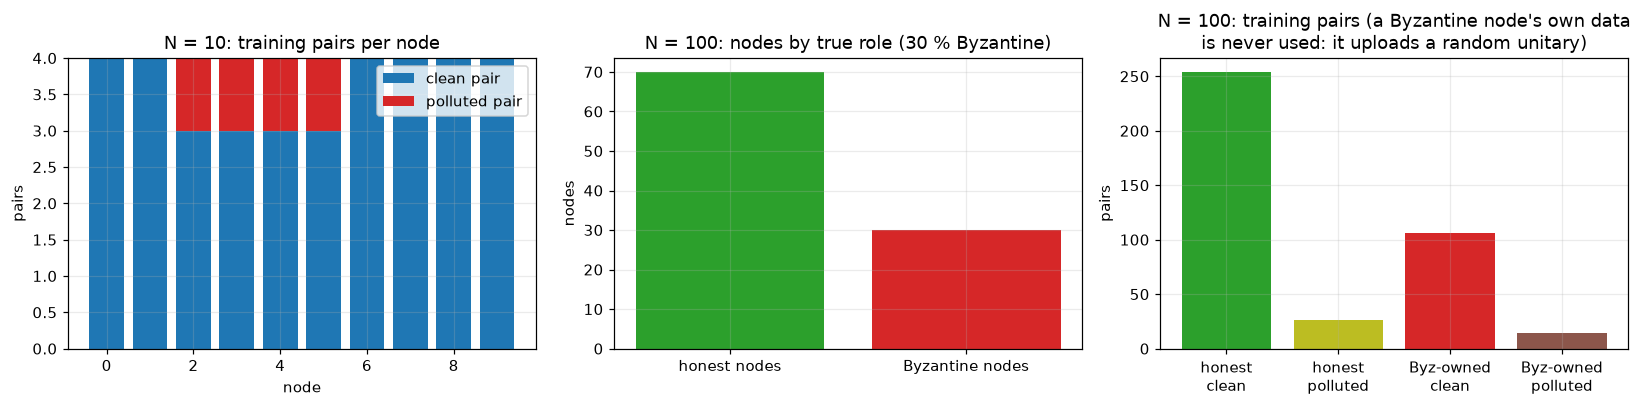

In [6]:
DS = {k: make_data(SEEDS[0], N, PAIRS_PER_NODE, N_TEST, N_REF, NOISY_FRAC) for k, (N, Np) in SCENARIOS.items()}
FEATS = [f"{part}(amp |{b}>)" for part in ("Re", "Im") for b in ("00", "01", "10", "11")]
BYZ = {k: byzantine_nodes(SEEDS[0], SCENARIOS[k][0], "gaussian") for k in SCENARIOS}

for k, d in DS.items():
    N, Np = SCENARIOS[k]
    print(f"=== scenario '{k}': N = {N} nodes, Np = {Np} per round, seed {SEEDS[0]} ===")
    print(f"training inputs  x : {d['x'].shape} complex  -> {2 * d['x'].shape[1]} real features: {FEATS}")
    print(f"training targets y : {d['y'].shape} complex (= Ug x for clean pairs);  test pairs {d['xt'].shape}, reference pairs {d['xr'].shape}")
    print(f"labels available   : owning node (0..{N-1}), polluted flag (0 = clean pair, 1 = random input/output pair), "
          f"owner is Byzantine (0/1)")
    print(f"polluted pairs     : {int(d['noisy'].sum())} of {len(d['noisy'])} ({d['noisy'].mean():.0%});  Byzantine nodes: {len(BYZ[k])} of {N}")
    print(f"pairs per node     : {np.bincount(d['node_of']).min()}..{np.bincount(d['node_of']).max()}")
print("\nThere are no class labels: the task is regression of a quantum state (learn the unitary Ug).  The ground-truth labels of the\n"
      "real observations are therefore the owning node (non-iid partition), the polluted flag, and whether the owner is Byzantine.")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
d = DS["all"]; N = SCENARIOS["all"][0]
clean = np.bincount(d["node_of"][~d["noisy"]], minlength=N); pol = np.bincount(d["node_of"][d["noisy"]], minlength=N)
ax[0].bar(range(N), clean, color="tab:blue", label="clean pair"); ax[0].bar(range(N), pol, bottom=clean, color="tab:red", label="polluted pair")
ax[0].set_title("N = 10: training pairs per node"); ax[0].set_xlabel("node"); ax[0].set_ylabel("pairs"); ax[0].legend()
d = DS["sel"]; N = SCENARIOS["sel"][0]
isb = np.array([n in BYZ["sel"] for n in range(N)])
ax[1].bar(["honest nodes", "Byzantine nodes"], [(~isb).sum(), isb.sum()], color=["tab:green", "tab:red"])
ax[1].set_title("N = 100: nodes by true role (30 % Byzantine)"); ax[1].set_ylabel("nodes")
pairs_by_role = [np.sum(~isb[d["node_of"]] & ~d["noisy"]), np.sum(~isb[d["node_of"]] & d["noisy"]),
                 np.sum(isb[d["node_of"]] & ~d["noisy"]), np.sum(isb[d["node_of"]] & d["noisy"])]
ax[2].bar(["honest\nclean", "honest\npolluted", "Byz-owned\nclean", "Byz-owned\npolluted"], pairs_by_role,
          color=["tab:green", "tab:olive", "tab:red", "tab:brown"])
ax[2].set_title("N = 100: training pairs (a Byzantine node's own data\nis never used: it uploads a random unitary)"); ax[2].set_ylabel("pairs")
plt.tight_layout(); plt.show()


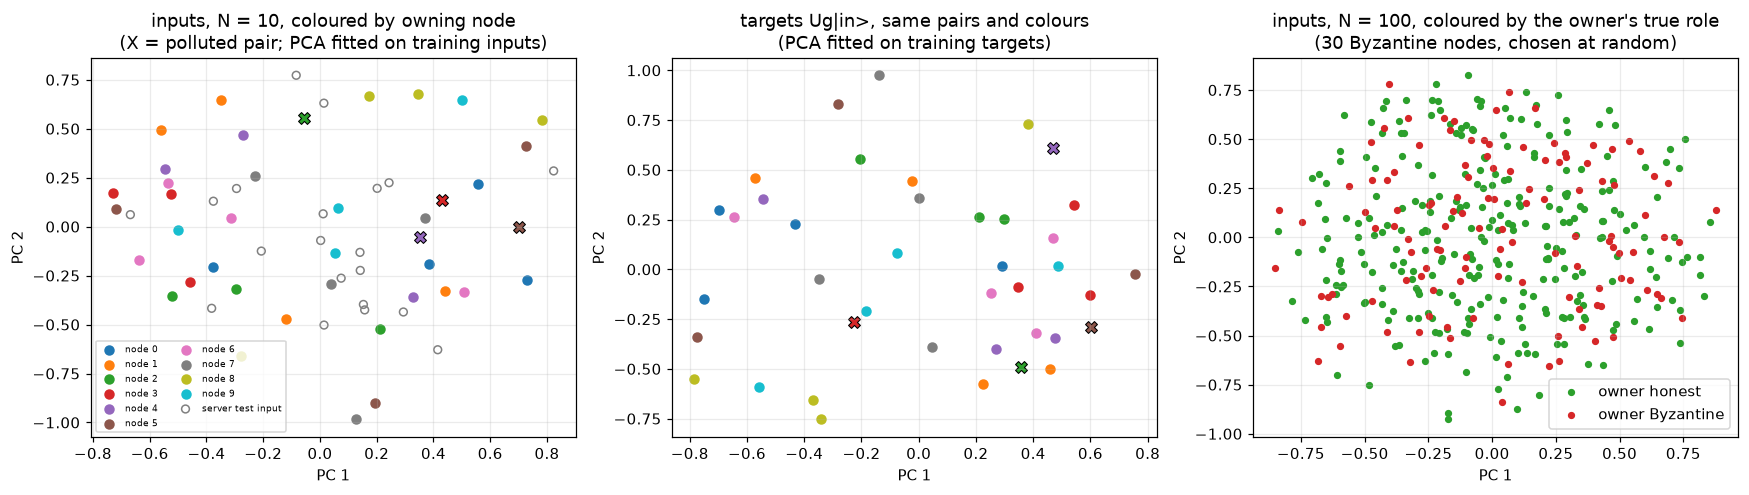

The model uses amplitude (state) encoding: the 4 complex amplitudes ARE the quantum input state, so there are no rotation angles
to scale to [0, pi]; the raw PCA coordinates above are the only 2-D view that applies.


In [7]:
# 2-D scatter of the REAL (synthetic-by-protocol) training observations, coloured by ground-truth label.
# The 4-amplitude input states are 8 real numbers; PCA is fitted on the TRAINING inputs only, the test inputs are projected with it.
def c2r_(z):
    return np.concatenate([z.real, z.imag], axis=1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
d = DS["all"]; N = SCENARIOS["all"][0]
pca_in = PCA(n_components=2, random_state=SEED).fit(c2r_(d["x"]))
Z, Zt = pca_in.transform(c2r_(d["x"])), pca_in.transform(c2r_(d["xt"]))
cmap = plt.get_cmap("tab10")
for n in range(N):
    m = (d["node_of"] == n) & ~d["noisy"]
    ax[0].scatter(Z[m, 0], Z[m, 1], s=34, color=cmap(n), label=f"node {n}")
    m = (d["node_of"] == n) & d["noisy"]
    ax[0].scatter(Z[m, 0], Z[m, 1], s=60, color=cmap(n), marker="X", edgecolor="k", linewidth=0.7)
ax[0].scatter(Zt[:, 0], Zt[:, 1], s=26, facecolors="none", edgecolors="grey", label="server test input")
ax[0].set_title("inputs, N = 10, coloured by owning node\n(X = polluted pair; PCA fitted on training inputs)")
ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2"); ax[0].legend(fontsize=6, ncol=2)

pca_out = PCA(n_components=2, random_state=SEED).fit(c2r_(d["y"]))
Zy = pca_out.transform(c2r_(d["y"]))
for n in range(N):
    m = (d["node_of"] == n) & ~d["noisy"]
    ax[1].scatter(Zy[m, 0], Zy[m, 1], s=34, color=cmap(n))
    m = (d["node_of"] == n) & d["noisy"]
    ax[1].scatter(Zy[m, 0], Zy[m, 1], s=60, color=cmap(n), marker="X", edgecolor="k", linewidth=0.7)
ax[1].set_title("targets Ug|in>, same pairs and colours\n(PCA fitted on training targets)"); ax[1].set_xlabel("PC 1"); ax[1].set_ylabel("PC 2")

d = DS["sel"]; N = SCENARIOS["sel"][0]
pca_s = PCA(n_components=2, random_state=SEED).fit(c2r_(d["x"]))
Zs = pca_s.transform(c2r_(d["x"]))
isb = np.array([n in BYZ["sel"] for n in range(N)])[d["node_of"]]
ax[2].scatter(Zs[~isb, 0], Zs[~isb, 1], s=14, color="tab:green", label="owner honest")
ax[2].scatter(Zs[isb, 0], Zs[isb, 1], s=14, color="tab:red", label="owner Byzantine")
ax[2].set_title("inputs, N = 100, coloured by the owner's true role\n(30 Byzantine nodes, chosen at random)"); ax[2].set_xlabel("PC 1"); ax[2].set_ylabel("PC 2"); ax[2].legend()
plt.tight_layout(); plt.show()
print("The model uses amplitude (state) encoding: the 4 complex amplitudes ARE the quantum input state, so there are no rotation angles\n"
      "to scale to [0, pi]; the raw PCA coordinates above are the only 2-D view that applies.")


received update unitaries: 120 (12 rounds x 10 nodes), each = the 704 complex entries of the 5 perceptron unitaries
honest updates   : 81, median Frobenius distance to the identity 0.017
Byzantine updates: 39, median Frobenius distance to the identity 10.644


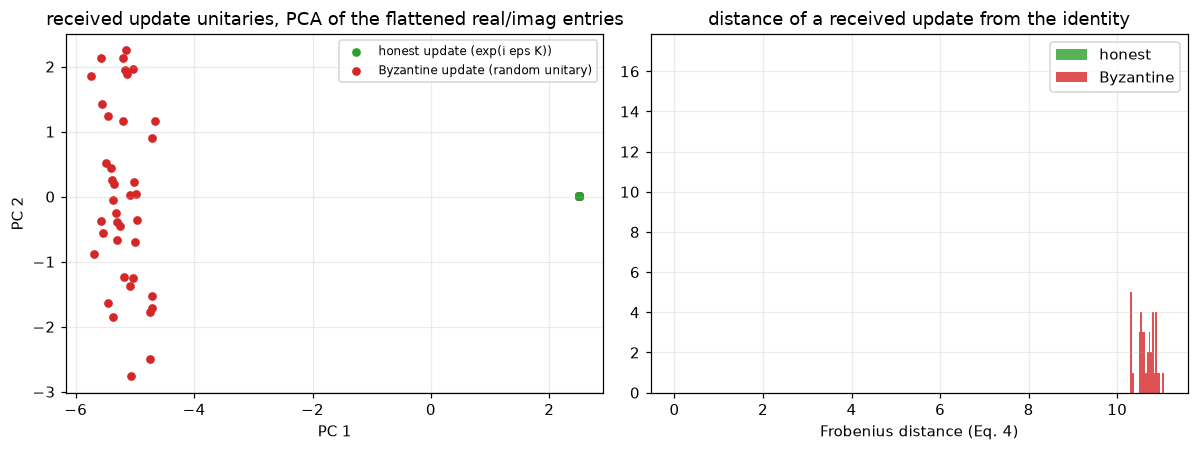

In [8]:
# The OTHER real observations of this paper are the update unitaries the server receives.  Record them for 12 rounds of the
# selected-node federation (N = 100, Np = 10, Gaussian attack, plain averaging) and colour every received update by its
# ground-truth origin (honest / Byzantine).  PCA is fitted on the received updates.
rec_run = run_qfl(SEEDS[0], "noop", "gaussian", SCENARIOS["sel"], 12, DS["sel"], record=True)
F = np.concatenate([r[0] for r in rec_run["rec"]]); isb = np.concatenate([r[1] for r in rec_run["rec"]])
Fr = np.concatenate([F.real, F.imag], axis=1)
dist_to_identity = np.linalg.norm(F - net.flat(net.identity_update()), axis=1)
print(f"received update unitaries: {F.shape[0]} (12 rounds x 10 nodes), each = the {F.shape[1]} complex entries of the 5 perceptron unitaries")
print(f"honest updates   : {int((~isb).sum())}, median Frobenius distance to the identity {np.median(dist_to_identity[~isb]):.3f}")
print(f"Byzantine updates: {int(isb.sum())}, median Frobenius distance to the identity {np.median(dist_to_identity[isb]):.3f}")
pcaU = PCA(n_components=2, random_state=SEED).fit(Fr)
ZU = pcaU.transform(Fr)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(ZU[~isb, 0], ZU[~isb, 1], s=22, color="tab:green", label="honest update (exp(i eps K))")
ax[0].scatter(ZU[isb, 0], ZU[isb, 1], s=22, color="tab:red", label="Byzantine update (random unitary)")
ax[0].set_title("received update unitaries, PCA of the flattened real/imag entries"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2"); ax[0].legend(fontsize=8)
ax[1].hist(dist_to_identity[~isb], bins=20, color="tab:green", alpha=0.8, label="honest"); ax[1].hist(dist_to_identity[isb], bins=20, color="tab:red", alpha=0.8, label="Byzantine")
ax[1].set_title("distance of a received update from the identity"); ax[1].set_xlabel("Frobenius distance (Eq. 4)"); ax[1].legend()
plt.tight_layout(); plt.show()


## Quantum Circuit Architecture

The DQNN is a circuit of unitary boxes. The cell below builds it as a **Qiskit circuit** (the object that is "executed"): input state preparation on `q0, q1`, the three layer-1 perceptron unitaries `U1,1 .. U1,3` (each on `q0, q1` and one hidden qubit),
the two layer-2 perceptron unitaries `U2,1, U2,2` (each on `q2, q3, q4` and one output qubit) and, to read the cost out, the inverse of the target state's preparation on the output qubits followed by a measurement: the probability of the outcome `00` is exactly the fidelity cost `<phi|rho_out|phi>`.
Tracing out the earlier layers (Eq. 1) is equivalent to simply never touching those qubits again, so the 7-qubit circuit and the layer-by-layer simulator must agree. The cell **asserts** that agreement for the random initial model and for a trained model, on every test input, and then draws and counts the circuit.

*Assumptions where the paper omits circuit details:* the perceptron unitaries are general unitaries of their 8- or 16-dimensional space (not a fixed gate set), as in Beer et al.; the hardware-level decomposition below is only the exact Qiskit synthesis and is not part of the training;
the measurement is added by this notebook only to show how the cost is read out.

random initial model: max |rho_out(Qiskit) - rho_out(simulator)| = 4.4e-16,  max |P(00) - fidelity cost| = 3.9e-16  over 20 test inputs


model after 20 clean rounds: max |rho_out(Qiskit) - rho_out(simulator)| = 5.6e-16,  max |P(00) - fidelity cost| = 7.8e-16  over 20 test inputs
The vectorised NumPy simulator used for every experiment equals the Qiskit circuit (asserted).


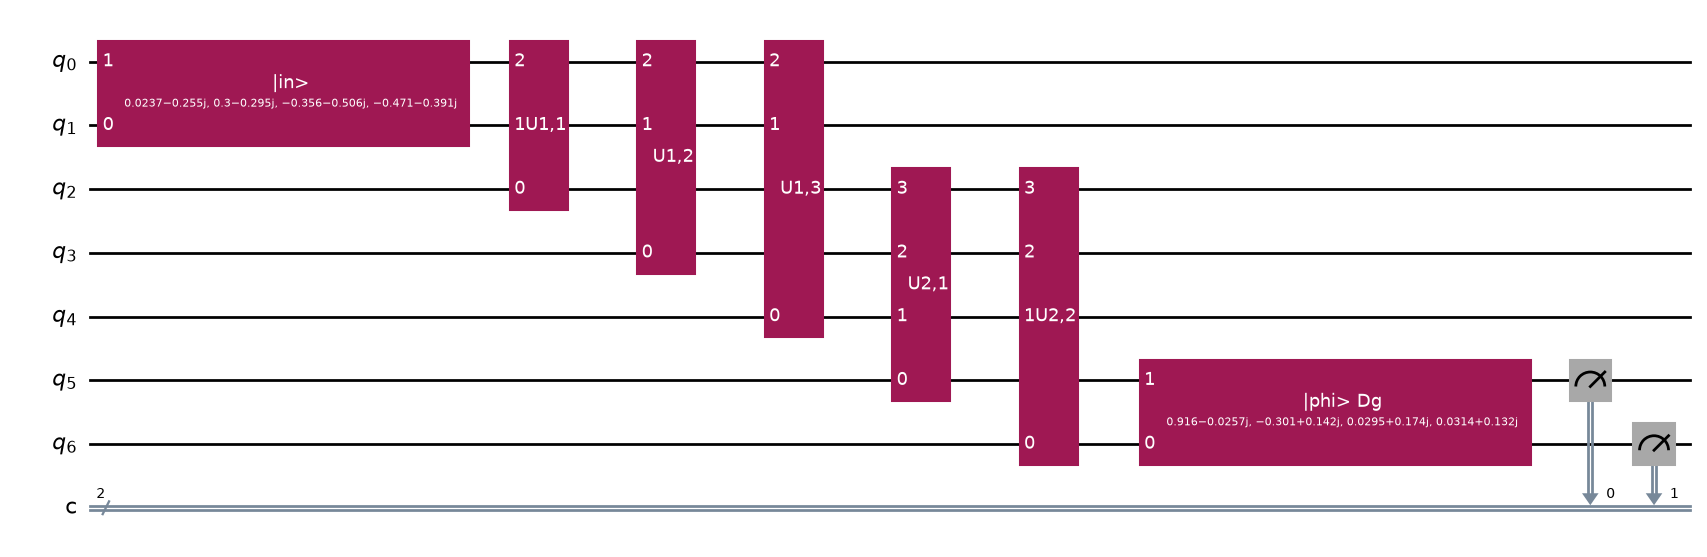

qubits                    : 7  (2 input + 3 hidden + 2 output)
depth (unitary boxes)     : 8  (state preparation, U1,1-U1,3 sequential on the shared inputs, U2,1-U2,2, inverse preparation, measurement)
depth after synthesis     : 501  into {'u': 486, 'cx': 249}  (exact synthesis of the 8x8 and 16x16 unitaries, optimisation_level=0)
trainable parameters      : 704 real numbers = 3 x 8^2 + 2 x 16^2 (each perceptron is a FULL unitary of a 2^(m_(l-1)+1)-dimensional space; the manifold has this many real dimensions, global phases included)
gates trained per layer   : layer 1: 3 unitaries on (in0, in1, hidden_j);  layer 2: 2 unitaries on (h0, h1, h2, out_j)


In [9]:
# The circuit that the simulator implements, built in Qiskit and compared with the simulator.
# Qubit map (Qiskit q0..q6):  input layer q0,q1 | hidden layer q2,q3,q4 | output layer q5,q6.
# The simulator numbers the qubits of a layer block with qubit 0 = most significant bit; Qiskit uses little-endian order,
# so the qubit lists are reversed when a perceptron unitary is appended.
LAYER_Q = [[0, 1, 2, 3, 4], [2, 3, 4, 5, 6]]           # global qubit of every qubit of layer block 1 and 2
SWAP_BITS = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]])   # converts Qiskit's order of the 2 output qubits

def build_circuit(U, x, phi=None, measure=False):
    q = QuantumRegister(7, "q")
    qc = QuantumCircuit(q, ClassicalRegister(2, "c")) if measure else QuantumCircuit(q)
    qc.append(StatePreparation(x, label="|in>"), [q[1], q[0]])                    # encoding: the 2-qubit input state
    for l in range(net.L):                                                          # layers: U_l = U_{l,m} ... U_{l,1}
        for j in range(ARCH[l + 1]):
            qs = [LAYER_Q[l][w] for w in net.wires[l][j]]                          # m_{l-1} input qubits + output qubit j
            qc.append(UnitaryGate(U[l][j], label=f"U{l+1},{j+1}"), [q[i] for i in reversed(qs)])
    if phi is not None:                                                             # cost = <phi|rho_out|phi> = P(00) after U_phi^dagger
        qc.append(StatePreparation(phi, label="|phi>").inverse(), [q[6], q[5]])
    if measure:
        qc.measure([5, 6], [0, 1])
    return qc

# a model that has learnt something: 20 clean all-node QuantumFed rounds
trained = run_qfl(SEEDS[0], "noop", "none", SCENARIOS["all"], 20, DS["all"])
U_demo, E_demo = trained["U"], net.embedded(trained["U"])
dd = DS["all"]
for name, UU in [("random initial model", net.init_params(np.random.default_rng(SEED))), ("model after 20 clean rounds", U_demo)]:
    EE = net.embedded(UU)
    worst_rho = worst_p = 0.0
    for i in range(len(dd["xt"])):
        x, y = dd["xt"][i], dd["yt"][i]
        rho_q = partial_trace(Statevector(build_circuit(UU, x)), [0, 1, 2, 3, 4]).data             # Qiskit: trace out input+hidden qubits
        rho_np = net.forward_out(EE, x[None])[0]                                                   # simulator: layer-by-layer partial traces
        worst_rho = max(worst_rho, np.abs(SWAP_BITS @ rho_q @ SWAP_BITS - rho_np).max())
        p00 = Statevector(build_circuit(UU, x, y)).probabilities([5, 6])[0]                        # circuit probability of the cost outcome
        worst_p = max(worst_p, abs(p00 - net.evaluate(EE, x[None], y[None])[0]))
    print(f"{name}: max |rho_out(Qiskit) - rho_out(simulator)| = {worst_rho:.1e},  max |P(00) - fidelity cost| = {worst_p:.1e}  "
          f"over {len(dd['xt'])} test inputs")
    assert worst_rho < 1e-10 and worst_p < 1e-10
print("The vectorised NumPy simulator used for every experiment equals the Qiskit circuit (asserted).")

x0, y0 = dd["xt"][0], dd["yt"][0]
qc_draw = build_circuit(U_demo, x0, y0, measure=True)
fig_c = qc_draw.draw("mpl", fold=-1, scale=0.9)
display(fig_c); plt.close(fig_c)

qc_plain = build_circuit(U_demo, x0)
tr = transpile(build_circuit(U_demo, x0, y0), basis_gates=["u", "cx"], optimization_level=0)
print(f"qubits                    : {qc_draw.num_qubits}  (2 input + 3 hidden + 2 output)")
print(f"depth (unitary boxes)     : {qc_draw.depth()}  (state preparation, U1,1-U1,3 sequential on the shared inputs, U2,1-U2,2, inverse preparation, measurement)")
print(f"depth after synthesis     : {tr.depth()}  into {dict(tr.count_ops())}  (exact synthesis of the 8x8 and 16x16 unitaries, optimisation_level=0)")
print(f"trainable parameters      : {net.n_params} real numbers = 3 x 8^2 + 2 x 16^2 (each perceptron is a FULL unitary of a "
      f"2^(m_(l-1)+1)-dimensional space; the manifold has this many real dimensions, global phases included)")
print(f"gates trained per layer   : layer 1: {ARCH[1]} unitaries on (in0, in1, hidden_j);  layer 2: {ARCH[2]} unitaries on (h0, h1, h2, out_j)")


## 3. The classical twins (not in the paper)

The abstract says the quantum versions behave like the classic versions. To check that on identical inputs, the same federation (same Ug, pairs, nodes, node schedule, Byzantine set) is trained with two classical models that map the 8 real numbers of the input state
(real and imaginary parts of 4 amplitudes) to 8 real numbers: a **linear** map (72 parameters, the classical counterpart of "a 4x4 matrix") and an **MLP with 16 tanh units** (280 parameters). Each node runs 5 local gradient steps on its pairs and uploads
the parameter change; the server adds the kept changes divided by the number of selected nodes. The Byzantine node uploads a Gaussian random vector (the analogue of the random unitary). FABA, Krum and ToFi are the original classical rules (Euclidean distance on the update vectors,
ToFi on the fidelity of the normalised prediction on the same reference pairs). The cost reported is the same fidelity `|<phi|y>|^2` of the normalised prediction, so the numbers are comparable.

In [10]:
# ================================================================== classical twins (linear map and MLP-16)
H = 16
D_IN = 8   # Re/Im of the 4 amplitudes

def c2r(z):
    return np.concatenate([z.real, z.imag], axis=-1)

def r2c(v):
    h = v.shape[-1] // 2
    return v[..., :h] + 1j * v[..., h:]

def init_theta(rng, kind='mlp'):
    if kind == 'linear':
        return np.concatenate([rng.normal(size=D_IN * D_IN) * np.sqrt(1.0 / D_IN), np.zeros(D_IN)])
    return np.concatenate([(rng.normal(size=H * D_IN) * np.sqrt(1.0 / D_IN)), np.zeros(H),
                           (rng.normal(size=D_IN * H) * np.sqrt(1.0 / H)), np.zeros(D_IN)])

def unpack(th):
    i = 0
    W1 = th[i:i + H * D_IN].reshape(H, D_IN); i += H * D_IN
    b1 = th[i:i + H]; i += H
    W2 = th[i:i + D_IN * H].reshape(D_IN, H); i += D_IN * H
    b2 = th[i:i + D_IN]
    return W1, b1, W2, b2

def predict(th, X):
    if len(th) == D_IN * D_IN + D_IN:
        return X @ th[:D_IN * D_IN].reshape(D_IN, D_IN).T + th[D_IN * D_IN:], None
    W1, b1, W2, b2 = unpack(th)
    h = np.tanh(X @ W1.T + b1)
    return h @ W2.T + b2, h

def grad(th, X, T):
    if len(th) == D_IN * D_IN + D_IN:
        P, _ = predict(th, X)
        dP = (P - T) / len(X)
        return np.concatenate([(dP.T @ X).ravel(), dP.sum(0)])
    W1, b1, W2, b2 = unpack(th)
    P, h = predict(th, X)
    n = len(X)
    dP = (P - T) / n
    gW2 = dP.T @ h; gb2 = dP.sum(0)
    dh = (dP @ W2) * (1 - h ** 2)
    gW1 = dh.T @ X; gb1 = dh.sum(0)
    return np.concatenate([gW1.ravel(), gb1, gW2.ravel(), gb2])

def metrics(th, X, T):
    P, _ = predict(th, X)
    y = r2c(P); t = r2c(T)
    y = y / np.linalg.norm(y, axis=1, keepdims=True)
    ov = np.einsum('na,na->n', t.conj(), y)
    fid = float(np.mean(np.abs(ov) ** 2))
    rho = np.einsum('na,nb->nab', y, y.conj()); tg = np.einsum('na,nb->nab', t, t.conj())
    mse = float(np.mean(np.sum(np.abs(rho - tg) ** 2, axis=(1, 2))))
    return fid, mse

def run_cl(seed, rule, attack, scenario, epochs, data, kind='linear', lr=CL_LR, local_steps=CL_LOCAL_STEPS, tau=1.2,
           alpha=ALPHA, sigma=CL_SIGMA, adaptive_grid=ADAPT_GRID, faba_literal=False, byz_frac=BYZ_FRAC):
    N, Np = scenario
    X = c2r(data["x"]); T = c2r(data["y"]); Xt = c2r(data["xt"]); Tt = c2r(data["yt"])
    Xr = c2r(data["xr"]); Tr = c2r(data["yr"])
    per_node = len(X) // N
    th = init_theta(np.random.default_rng(20_000 + seed), kind)
    byz_set = byzantine_nodes(seed, N, attack, byz_frac)          # the same Byzantine nodes as in the quantum run
    fid, mse, nbyz_kept, nbyz_sel = [], [], [], []
    f, m = metrics(th, Xt, Tt); fid.append(f); mse.append(m)
    for ep in range(epochs):
        rs = np.random.default_rng(40_000 + 1000 * seed + ep)
        sel = np.arange(N) if Np == N else np.sort(rs.choice(N, Np, replace=False))
        sel = sel.tolist()
        honest_ids = [n for n in sel if n not in byz_set]
        byz_ids = [n for n in sel if n in byz_set]
        delta = {}
        for n in honest_ids:
            sl = slice(n * per_node, (n + 1) * per_node)
            t_ = th.copy()
            for _ in range(local_steps):
                t_ = t_ - lr * grad(t_, X[sl], T[sl])
            delta[n] = t_ - th
        ra = np.random.default_rng(50_000 + 1000 * seed + ep)

        def agg(upd_list):
            F = np.stack(upd_list)
            if rule == "noop":
                return list(range(len(upd_list)))
            if rule == "faba":
                return agg_faba(F, alpha, faba_literal)
            if rule == "krum":
                return agg_krum(F, alpha)
            if rule == "tofi":
                ls = [metrics(th + u, Xr, Tr)[0] for u in upd_list]
                return agg_tofi(ls, tau)
        if byz_ids:
            if attack == "gaussian":
                for n in byz_ids:
                    delta[n] = ra.normal(scale=sigma, size=th.shape)
            elif attack == "adaptive":
                if honest_ids:
                    mean_h = np.mean([delta[n] for n in honest_ids], axis=0)
                    best = np.zeros_like(mean_h)
                    for s in adaptive_grid:
                        cand = -s * mean_h
                        lst = [delta[n] for n in honest_ids] + [cand] * len(byz_ids)
                        kept = agg(lst)
                        if s == 0 or all((len(honest_ids) + b) in kept for b in range(len(byz_ids))):
                            best = cand
                else:
                    best = np.zeros_like(th)
                for n in byz_ids:
                    delta[n] = best
        ids = sel
        upd_list = [delta[n] for n in ids]
        kept = agg(upd_list)
        nbyz_sel.append(len(byz_ids)); nbyz_kept.append(sum(1 for k in kept if ids[k] in byz_set))
        th = np.clip(th + np.sum([upd_list[k] for k in kept], axis=0) / len(ids), -1e3, 1e3)
        f, m = metrics(th, Xt, Tt); fid.append(f); mse.append(m)
    return dict(fid=np.array(fid), mse=np.array(mse), nbyz_sel=np.array(nbyz_sel), nbyz_kept=np.array(nbyz_kept))


### 3b. Choosing ToFi's threshold on a validation seed

The paper does not give `tau`. A different random problem (validation seed 1000: another `Ug`, other data, other Byzantine nodes, another initial model) is trained for `TUNE_EPOCHS` rounds under the Gaussian attack in both scenarios for each `tau` of the grid, and the value with the best average final
fidelity is used for every experiment. The test curves of the real seeds never influence this choice.

In [11]:
# ToFi's threshold tau is not given in the paper.  Pick it on a VALIDATION seed (a different random Ug, different data, different
# initial model and different Byzantine nodes than every seed of the experiments), under the Gaussian attack, for both scenarios.
rows = []
t0 = time.time()
for k, sc in SCENARIOS.items():
    dv = make_data(TUNE_SEED, sc[0], PAIRS_PER_NODE, N_TEST, N_REF, NOISY_FRAC)
    for tau in TAU_GRID:
        r = run_qfl(TUNE_SEED, "tofi", "gaussian", sc, TUNE_EPOCHS, dv, tau=tau)
        c = run_cl(TUNE_SEED, "tofi", "gaussian", sc, TUNE_EPOCHS, dv, kind="linear", tau=tau)
        rows.append(dict(scenario=k, tau=tau, qnn_fidelity=r["fid"][-5:].mean(), qnn_byz_kept=f"{r['nbyz_kept'].sum()}/{r['nbyz_sel'].sum()}",
                         classical_fidelity=c["fid"][-5:].mean(), classical_byz_kept=f"{c['nbyz_kept'].sum()}/{c['nbyz_sel'].sum()}"))
tune = pd.DataFrame(rows)
display(tune.round(3))
TAU_Q = float(tune.groupby("tau")["qnn_fidelity"].mean().idxmax())
TAU_C = float(tune.groupby("tau")["classical_fidelity"].mean().idxmax())
print(f"validation seed {TUNE_SEED}, {TUNE_EPOCHS} rounds -> tau (quantum ToFi) = {TAU_Q}, tau (classical ToFi twin) = {TAU_C}   [{time.time()-t0:.0f} s]")


,scenario,tau,qnn_fidelity,qnn_byz_kept,classical_fidelity,classical_byz_kept
0,all,1.0,0.901,8/180,0.870,15/180
1,all,1.2,0.901,8/180,0.872,17/180
2,all,1.6,0.883,15/180,0.878,18/180
3,all,2.0,0.869,10/180,0.882,22/180
4,sel,1.0,0.967,34/180,0.988,3/180
5,sel,1.2,0.457,51/180,0.986,4/180
6,sel,1.6,0.656,45/180,0.986,7/180
7,sel,2.0,0.257,98/180,0.898,17/180


validation seed 1000, 60 rounds -> tau (quantum ToFi) = 1.0, tau (classical ToFi twin) = 1.6   [338 s]


## 4. The experiments: every rule, both scenarios, all environments

For every seed and both scenarios (all nodes N = 10, selected nodes 10 of 100) the following runs are made, for the quantum model and for both classical twins:

* **No Byzantine** (all nodes honest, plain averaging): the target the defences try to reach;
* **Byzantine environment** (30 % Gaussian attackers): No Operation (plain averaging), FABA, Krum, ToFi;
* **clean environment** (nobody attacks): FABA, Krum, ToFi (what the rules cost when there is nothing to defend), the "No Operation" curve is the No-Byzantine run;
* **adaptive attack** (Section 6): the same four rules against attackers that know the rule;
* in the all-node scenario also FABA exactly as printed in Algorithm 1 (`faba_literal`).

Each line printed below is one quantum run; the classical twins run silently in between.

In [12]:
RES = {}      # (model, scenario, env, rule) -> list over seeds of dict(fid, mse, nbyz_sel, nbyz_kept, nkept, secs)
PLAN = [("ideal", "noop", "none"),                                                    # nobody is Byzantine, plain averaging  = "No Byzantine"
        ("byz", "noop", "gaussian"), ("byz", "faba", "gaussian"), ("byz", "krum", "gaussian"), ("byz", "tofi", "gaussian"),
        ("clean", "faba", "none"), ("clean", "krum", "none"), ("clean", "tofi", "none"),   # the defences when nobody attacks
        ("adapt", "noop", "adaptive"), ("adapt", "faba", "adaptive"), ("adapt", "krum", "adaptive"), ("adapt", "tofi", "adaptive")]
MODELS = {"qnn": "quantum QuantumFed [2,3,2]", "lin": "classical linear twin", "mlp": "classical MLP-16 twin"}

def run_suite(models=("qnn", "lin", "mlp")):
    t_all = time.time()
    for seed in SEEDS:
        for sk, sc in SCENARIOS.items():
            data = make_data(seed, sc[0], PAIRS_PER_NODE, N_TEST, N_REF, NOISY_FRAC)
            plan = list(PLAN) + ([("byz_literal", "faba_literal", "gaussian")] if sk == "all" else [])
            for env, rule, attack in plan:
                for model in models:
                    t = time.time()
                    rl = "faba" if rule == "faba_literal" else rule
                    if model == "qnn":
                        r = run_qfl(seed, rl, attack, sc, EPOCHS, data, tau=TAU_Q, faba_literal=(rule == "faba_literal"))
                    else:
                        r = run_cl(seed, rl, attack, sc, EPOCHS, data, kind={"lin": "linear", "mlp": "mlp"}[model], tau=TAU_C, faba_literal=(rule == "faba_literal"))
                    r = {k: r[k] for k in ("fid", "mse", "nbyz_sel", "nbyz_kept")} | {"nkept": r.get("nkept"), "secs": time.time() - t}
                    RES.setdefault((model, sk, env, rule), []).append(r)
                    if model == "qnn":
                        print(f"seed {seed} | {sk:3s} | {env:11s} | {rule:12s} | final fidelity {r['fid'][-10:].mean():.3f} | "
                              f"Byzantine updates kept {int(r['nbyz_kept'].sum())}/{int(r['nbyz_sel'].sum())} | {r['secs']:.0f} s", flush=True)
    print(f"suite finished in {(time.time()-t_all)/60:.1f} min")

run_suite()


seed 0 | all | ideal       | noop         | final fidelity 0.998 | Byzantine updates kept 0/0 | 23 s


seed 0 | all | byz         | noop         | final fidelity 0.251 | Byzantine updates kept 240/240 | 28 s


seed 0 | all | byz         | faba         | final fidelity 0.988 | Byzantine updates kept 0/240 | 12 s


seed 0 | all | byz         | krum         | final fidelity 0.376 | Byzantine updates kept 0/240 | 32 s


seed 0 | all | byz         | tofi         | final fidelity 0.976 | Byzantine updates kept 2/240 | 18 s


...

seed 1 | sel | adapt       | noop         | final fidelity 0.221 | Byzantine updates kept 225/225 | 6 s


seed 1 | sel | adapt       | faba         | final fidelity 0.214 | Byzantine updates kept 225/225 | 17 s


seed 1 | sel | adapt       | krum         | final fidelity 0.255 | Byzantine updates kept 78/225 | 30 s


seed 1 | sel | adapt       | tofi         | final fidelity 0.984 | Byzantine updates kept 0/225 | 28 s


suite finished in 34.2 min


## 5. Re-drawing the paper's figures

**Fig. 3** (all-node participation): left the Byzantine environment, right the clean environment; top the fidelity cost (higher is better), bottom the MSE (lower is better). Curves are the mean over seeds, the band is one standard deviation.
No-Byzantine is plotted dashed in black in both columns; the clean environment's "No Operation" curve is the same run.

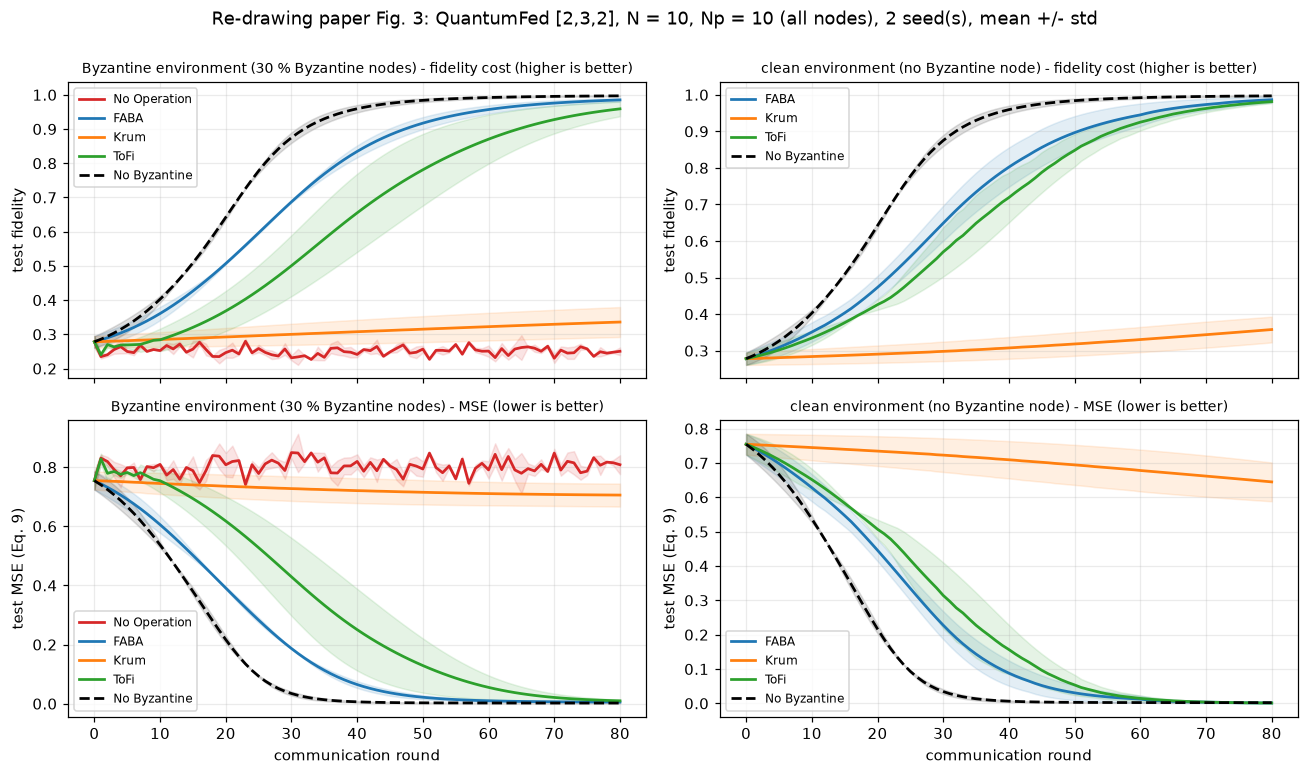

In [13]:
COL = {"noop": "tab:red", "faba": "tab:blue", "krum": "tab:orange", "tofi": "tab:green", "ideal": "black"}
LAB = {"noop": "No Operation", "faba": "FABA", "krum": "Krum", "tofi": "ToFi", "ideal": "No Byzantine"}

def curves(model, sk, env, rule, key="fid"):
    return np.stack([r[key] for r in RES[(model, sk, env, rule)]])

def plot_fig(model, sk, title):
    fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    for row, key in enumerate(("fid", "mse")):
        for col, (env, rules) in enumerate((("byz", ["noop", "faba", "krum", "tofi"]), ("clean", ["faba", "krum", "tofi"]))):
            a = ax[row, col]
            for rule in rules + ["ideal"]:
                C = curves(model, sk, "ideal" if rule == "ideal" else env, "noop" if rule == "ideal" else rule, key)
                m, s = C.mean(0), C.std(0)
                x = np.arange(len(m))
                a.plot(x, m, color=COL[rule], lw=1.8, ls="--" if rule == "ideal" else "-", label=LAB[rule])
                if len(C) > 1:
                    a.fill_between(x, m - s, m + s, color=COL[rule], alpha=0.12)
            a.set_title(("Byzantine environment (30 % Byzantine nodes)" if env == "byz" else "clean environment (no Byzantine node)")
                        + (" - fidelity cost (higher is better)" if key == "fid" else " - MSE (lower is better)"), fontsize=9)
            a.set_ylabel("test fidelity" if key == "fid" else "test MSE (Eq. 9)")
            if row == 1:
                a.set_xlabel("communication round")
            a.legend(fontsize=8)
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()

plot_fig("qnn", "all", f"Re-drawing paper Fig. 3: QuantumFed [2,3,2], N = 10, Np = 10 (all nodes), {len(SEEDS)} seed(s), mean +/- std")


**Fig. 4** (selected-node participation, 10 of 100 nodes per round, 30 Byzantine nodes among the 100). The number of Byzantine nodes among the 10 selected varies from round to round (3 on average), which is what separates the rules.

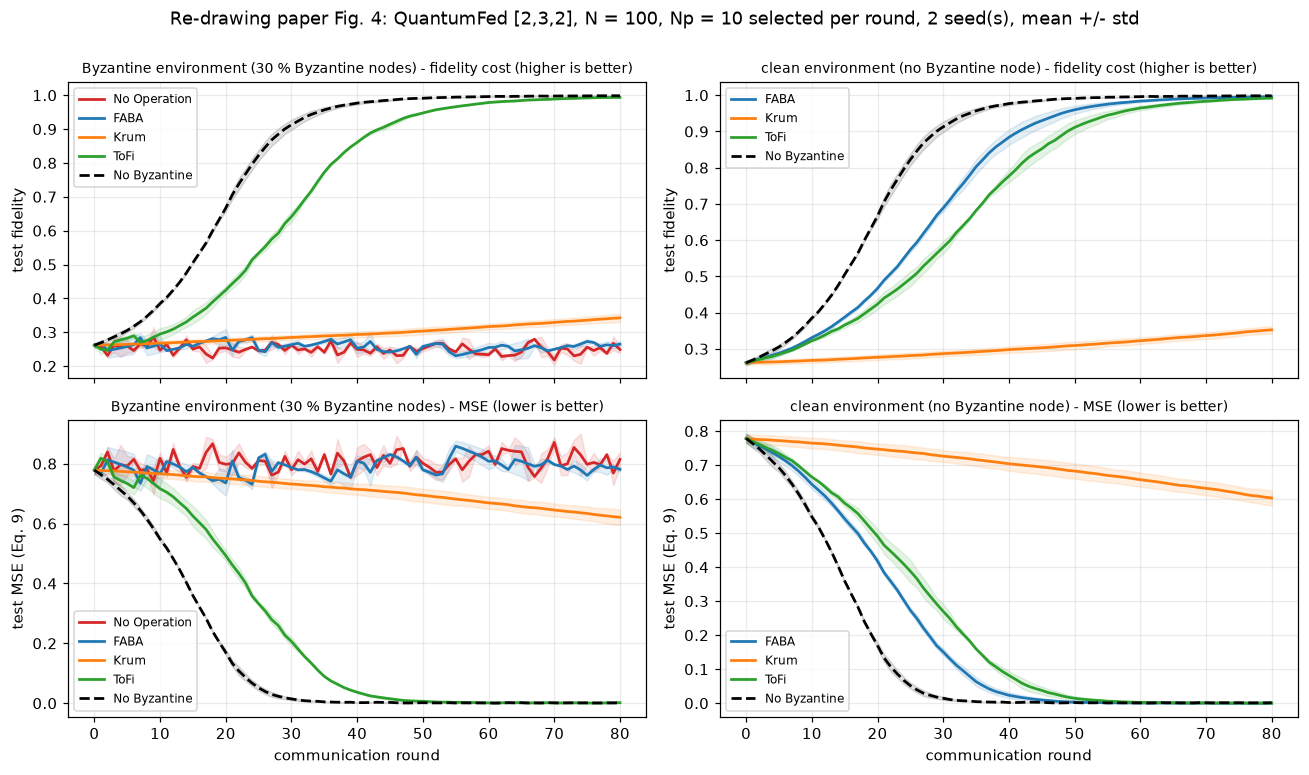

In [14]:
plot_fig("qnn", "sel", f"Re-drawing paper Fig. 4: QuantumFed [2,3,2], N = 100, Np = 10 selected per round, {len(SEEDS)} seed(s), mean +/- std")


### 5b. Summary table, all rules

In [15]:
def stat(model, sk, env, rule):
    F, M = curves(model, sk, env, rule, "fid"), curves(model, sk, env, rule, "mse")
    fin = F[:, -10:].mean(1)
    mean_curve = F.mean(0)
    e90 = int(np.argmax(mean_curve >= 0.9)) if (mean_curve >= 0.9).any() else np.inf
    sel_ = sum(int(r["nbyz_sel"].sum()) for r in RES[(model, sk, env, rule)])
    kept_ = sum(int(r["nbyz_kept"].sum()) for r in RES[(model, sk, env, rule)])
    return dict(final_fid=fin.mean(), final_fid_sd=fin.std(), final_mse=M[:, -10:].mean(), rounds_to_0p9=e90,
                instability=F[:, -20:].std(axis=1).mean(), byz_kept=kept_, byz_sent=sel_,
                secs=np.mean([r["secs"] for r in RES[(model, sk, env, rule)]]))

rows = []
for model in MODELS:
    for sk in SCENARIOS:
        keys = [k for k in RES if k[0] == model and k[1] == sk]
        for (_, _, env, rule) in keys:
            rows.append(dict(model=model, scenario=sk, env=env, rule=rule, **stat(model, sk, env, rule)))
SUMMARY = pd.DataFrame(rows)
SUMMARY["env"] = SUMMARY["env"].map({"ideal": "no Byzantine", "byz": "Gaussian attack", "clean": "clean + defence",
                                     "adapt": "adaptive attack", "byz_literal": "Gaussian attack"})
pd.set_option("display.width", 200, "display.max_columns", 30)
display(SUMMARY[SUMMARY.model == "qnn"].drop(columns="model").round(3).reset_index(drop=True))
print("final_fid = test fidelity cost averaged over the last 10 rounds (mean over seeds, sd over seeds); rounds_to_0p9 = first round at which the\n"
      "seed-averaged curve reaches 0.9 (inf = never); instability = sd of the fidelity over the last 20 rounds; byz_kept/byz_sent = Byzantine updates\n"
      "that survived the rule / were uploaded.")


,scenario,env,rule,final_fid,final_fid_sd,final_mse,rounds_to_0p9,instability,byz_kept,byz_sent,secs
0,all,no Byzantine,noop,0.996,0.001,0.002,32.0,0.001,0,0,24.344
1,all,Gaussian attack,noop,0.249,0.001,0.807,inf,0.017,480,480,19.704
2,all,Gaussian attack,faba,0.981,0.006,0.006,48.0,0.008,0,480,19.923
3,all,Gaussian attack,krum,0.333,0.043,0.707,inf,0.004,0,480,28.602
4,all,Gaussian attack,tofi,0.947,0.029,0.014,65.0,0.025,12,480,30.601
5,all,clean + defence,faba,0.981,0.011,0.002,51.0,0.011,0,0,18.520
6,all,clean + defence,krum,0.351,0.035,0.653,inf,0.008,0,0,23.070
7,all,clean + defence,tofi,0.974,0.007,0.002,56.0,0.016,0,0,48.847
8,all,adaptive attack,noop,0.202,0.007,1.066,inf,0.001,480,480,18.290
9,all,adaptive attack,faba,0.218,0.000,0.898,inf,0.001,480,480,36.532


final_fid = test fidelity cost averaged over the last 10 rounds (mean over seeds, sd over seeds); rounds_to_0p9 = first round at which the
seed-averaged curve reaches 0.9 (inf = never); instability = sd of the fidelity over the last 20 rounds; byz_kept/byz_sent = Byzantine updates
that survived the rule / were uploaded.


### 5c. The classical twins under the same protocol

Same figure layout for the classical linear twin, and the summary rows of both classical twins (without the adaptive attack, which is in Section 6).

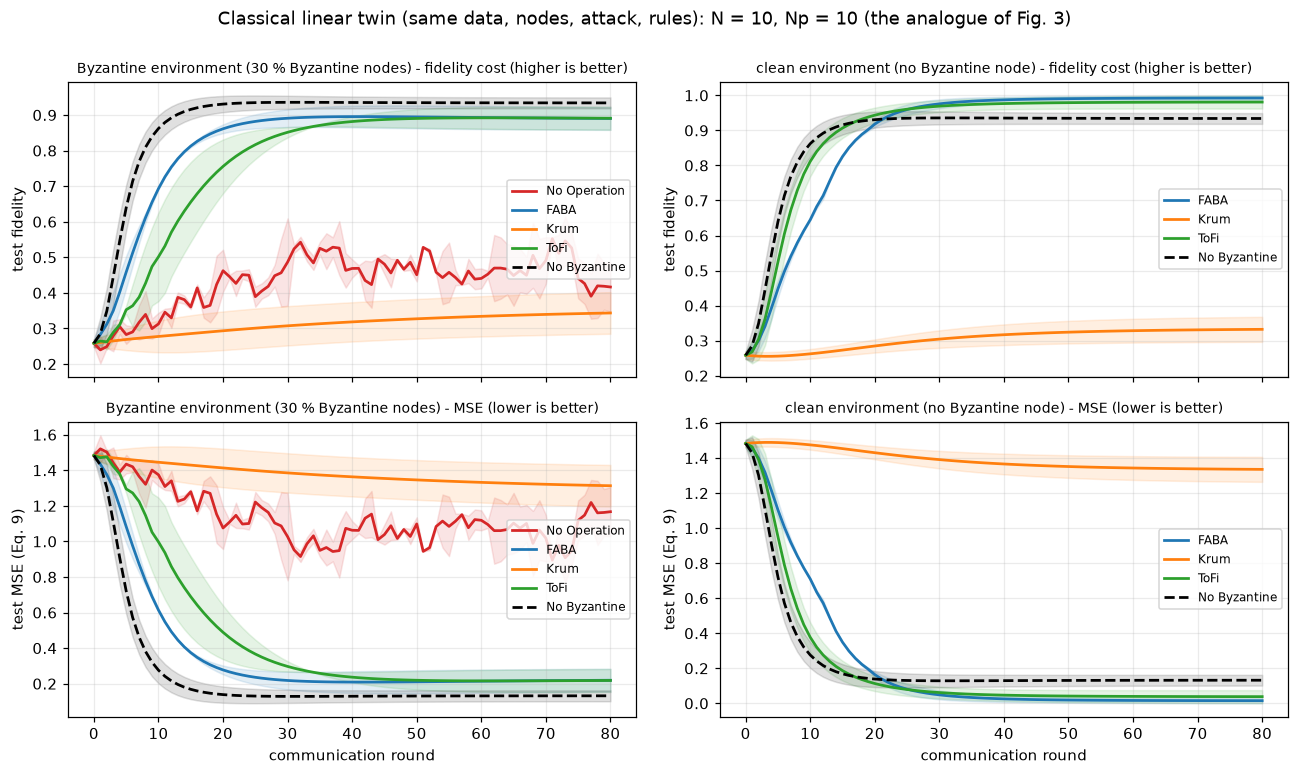

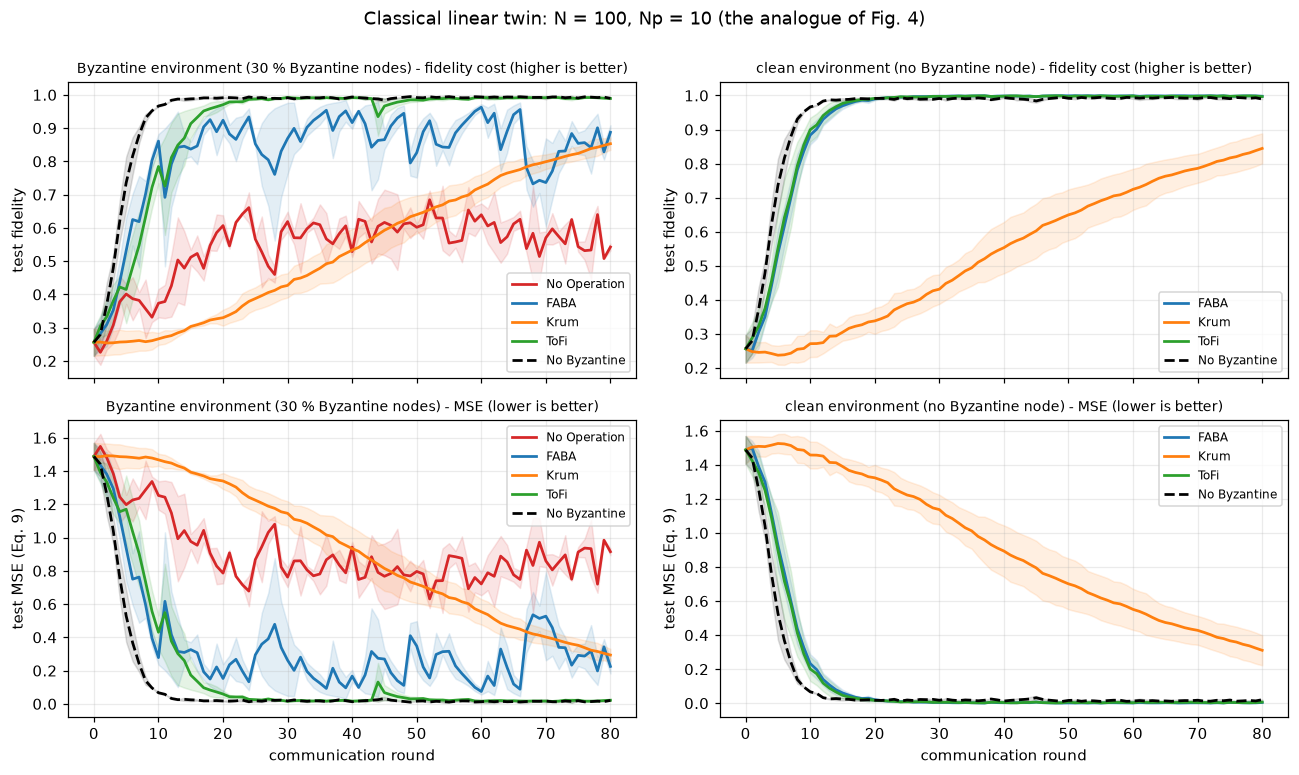

,model,scenario,env,rule,final_fid,final_fid_sd,final_mse,rounds_to_0p9,instability,byz_kept,byz_sent,secs
0,lin,all,no Byzantine,noop,0.934,0.015,0.132,13.0,0.000,0,0,2.152
1,lin,all,Gaussian attack,noop,0.465,0.057,1.070,inf,0.049,480,480,2.187
2,lin,all,Gaussian attack,faba,0.891,0.032,0.218,inf,0.001,0,480,3.318
3,lin,all,Gaussian attack,krum,0.342,0.058,1.317,inf,0.003,0,480,1.470
4,lin,all,Gaussian attack,tofi,0.891,0.032,0.217,inf,0.001,25,480,2.554
5,lin,all,clean + defence,faba,0.992,0.007,0.015,19.0,0.000,0,0,2.082
6,lin,all,clean + defence,krum,0.332,0.035,1.337,inf,0.001,0,0,1.473
7,lin,all,clean + defence,tofi,0.981,0.018,0.038,15.0,0.000,0,0,1.755
8,lin,all,Gaussian attack,faba_literal,0.673,0.108,0.653,inf,0.030,160,480,1.042
9,lin,sel,no Byzantine,noop,0.992,0.001,0.015,8.0,0.002,0,0,2.806


In [16]:
plot_fig("lin", "all", "Classical linear twin (same data, nodes, attack, rules): N = 10, Np = 10 (the analogue of Fig. 3)")
plot_fig("lin", "sel", "Classical linear twin: N = 100, Np = 10 (the analogue of Fig. 4)")
t = SUMMARY[(SUMMARY.model != "qnn") & (SUMMARY.env != "adaptive attack")].copy()
display(t.round(3).reset_index(drop=True))


## 6. Control experiment: an attacker that knows the aggregation rule

The paper's Byzantine node is oblivious: a random unitary, which is far from every honest update and therefore easy to isolate. A defence that only works against this attacker is a weak defence. The control below lets the Byzantine nodes **collude**, **know the rule** and the honest updates,
and (for ToFi) even the server's reference data. Every round they compute the honest average direction `K_bar`, reverse it and upload `exp(-i eps s K_bar)` with the largest step `s` of `ADAPT_GRID` for which the real rule, run on the honest updates plus their candidate,
still keeps all their updates (`s = 0`, the identity, is the fall-back). This is not a claim of the paper and is not counted in its verdict table; it shows how much of the "defends" verdict is specific to the random-unitary attack.
The classical twin gets the same attacker (reversed honest mean update times `s`).

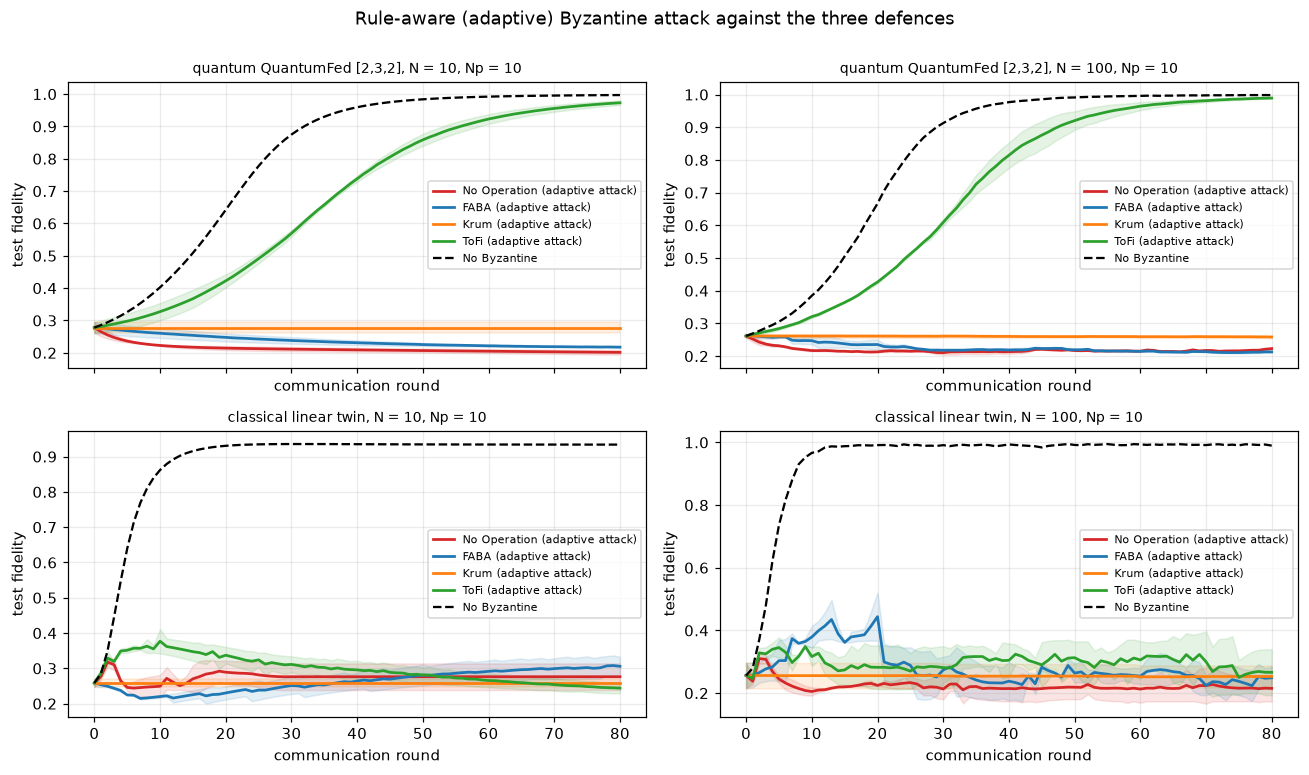

,model,scenario,rule,recovery_gaussian,recovery_adaptive,adaptive_byz_kept
0,qnn,all,faba,0.980,0.020,480/480
1,qnn,all,krum,0.112,0.096,160/480
2,qnn,all,tofi,0.933,0.962,0/480
3,qnn,sel,faba,0.020,-0.008,446/446
4,qnn,sel,krum,0.118,0.053,157/446
5,qnn,sel,tofi,0.992,0.985,14/446
6,lin,all,faba,0.908,0.040,480/480
7,lin,all,krum,-0.262,-0.027,160/480
8,lin,all,tofi,0.909,-0.043,447/480
9,lin,sel,faba,0.663,0.026,437/446


recovery = (final fidelity of the rule - final fidelity of No Operation under the same attack) / (final fidelity with nobody Byzantine - final fidelity of
No Operation).  1 = the rule restores the Byzantine-free result, 0 = it is no better than plain averaging.


In [17]:
# Control experiment that is NOT in the paper: colluding Byzantine nodes that know the aggregation rule.  Each round they take the honest
# nodes' average update direction K_bar, reverse it, and upload exp(-i eps s K_bar) with the LARGEST step s of ADAPT_GRID for which the
# real rule (FABA / Krum / ToFi, run on the honest updates + their candidate) still keeps all their updates.  They are given the reference
# data of ToFi (worst case).  s = 0 is the identity update (a harmless free-rider).
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for i, model in enumerate(("qnn", "lin")):
    for j, sk in enumerate(SCENARIOS):
        a = ax[i, j]
        for rule in ("noop", "faba", "krum", "tofi"):
            C = curves(model, sk, "adapt", rule); m = C.mean(0)
            a.plot(m, color=COL[rule], lw=1.8, label=LAB[rule] + " (adaptive attack)")
            if len(C) > 1:
                a.fill_between(np.arange(len(m)), m - C.std(0), m + C.std(0), color=COL[rule], alpha=0.12)
        a.plot(curves(model, sk, "ideal", "noop").mean(0), color="black", ls="--", label="No Byzantine")
        a.set_title(f"{MODELS[model]}, N = {SCENARIOS[sk][0]}, Np = {SCENARIOS[sk][1]}", fontsize=9)
        a.set_ylabel("test fidelity"); a.set_xlabel("communication round"); a.legend(fontsize=7)
plt.suptitle("Rule-aware (adaptive) Byzantine attack against the three defences", y=1.0); plt.tight_layout(); plt.show()

def recovery(model, sk, env, rule):
    f = stat(model, sk, env, rule)["final_fid"]
    f_noop = stat(model, sk, env, "noop")["final_fid"]            # No Operation under the SAME attack
    f_ideal = stat(model, sk, "ideal", "noop")["final_fid"]
    return (f - f_noop) / (f_ideal - f_noop)

rows = []
for model in ("qnn", "lin", "mlp"):
    for sk in SCENARIOS:
        for rule in ("faba", "krum", "tofi"):
            ad = stat(model, sk, "adapt", rule)
            rows.append(dict(model=model, scenario=sk, rule=rule,
                             recovery_gaussian=recovery(model, sk, "byz", rule), recovery_adaptive=recovery(model, sk, "adapt", rule),
                             adaptive_byz_kept=f"{ad['byz_kept']}/{ad['byz_sent']}"))
ADAPT = pd.DataFrame(rows)
display(ADAPT.round(3))
print("recovery = (final fidelity of the rule - final fidelity of No Operation under the same attack) / (final fidelity with nobody Byzantine - final fidelity of\nNo Operation).  1 = the rule restores the Byzantine-free result, 0 = it is no better than plain averaging.")


## 7. Median rules: why the paper drops them (illustration)

Sec. III-E argues that median-based aggregation does not carry over to unitaries. One concrete obstacle can be checked numerically: an element-wise mean or median of unitary matrices is, in general, not a unitary, so it cannot be applied to the network as a gate.
The cell measures `||M^dagger M - I||` for the honest update unitaries of the all-node scenario and for a set with three random Byzantine unitaries.

In [18]:
# Paper Sec. III-E argues that a median-type aggregate does not exist "in unitary space".  A quick numerical illustration (this does not
# prove the paper's argument, it only shows the first obstacle): the element-wise median / mean of unitaries is not unitary.
# Honest update unitaries of the 10 nodes of the all-node scenario at the initial model, element-wise real/imag median per entry.
dd = DS["all"]; netc = DQNN(ARCH)
Uini = netc.init_params(np.random.default_rng(20_000 + SEEDS[0])); Eini = netc.embedded(Uini)
upd = []
for n in range(10):
    sl = slice(n * PAIRS_PER_NODE, (n + 1) * PAIRS_PER_NODE)
    upd.append(netc.to_unitary_update(netc.update_matrices(Uini, Eini, dd["x"][sl], dd["y"][sl], ETA, 10 * PAIRS_PER_NODE), EPS))
def defect(M):
    return np.linalg.norm(M.conj().T @ M - np.eye(len(M)))
rows = []
for (l, j) in [(0, 0), (1, 0)]:
    stack = np.stack([u[l][j] for u in upd])
    med = np.median(stack.real, axis=0) + 1j * np.median(stack.imag, axis=0)
    rows.append(dict(perceptron=f"U{l+1},{j+1} ({len(med)}x{len(med)})", defect_mean=defect(stack.mean(0)), defect_median=defect(med),
                     defect_single_update=np.mean([defect(u[l][j]) for u in upd])))
byz = [byzantine_unitary(16, np.random.default_rng(i)) for i in range(3)]
stack = np.stack([u[1][0] for u in upd[:7]] + byz)
med = np.median(stack.real, axis=0) + 1j * np.median(stack.imag, axis=0)
rows.append(dict(perceptron="U2,1 with 3 random Byzantine unitaries", defect_mean=defect(stack.mean(0)), defect_median=defect(med), defect_single_update=0.0))
display(pd.DataFrame(rows).style.format({c: '{:.2e}' for c in ('defect_mean', 'defect_median', 'defect_single_update')}))
print("defect = ||M^dagger M - I||_F.  Each honest update is unitary; the element-wise mean/median of near-identity honest updates is unitary only to\n"
      "second order (see the small numbers), and with 3 random Byzantine unitaries among 10 the mean is far from unitary (defect ~ 2) while the element-wise\n"
      "median stays close to the identity.  So non-unitarity alone does not rule a median out here; the paper's other objection (what the median of unitaries\n"
      "MEANS, and that QuantumFed applies updates one after the other) is a modelling argument that this notebook does not test.")


,perceptron,defect_mean,defect_median,defect_single_update
0,"U1,1 (8x8)",4.42e-06,4.69e-06,4.55e-15
1,"U2,1 (16x16)",3.78e-05,4.50e-05,8.56e-15
2,"U2,1 with 3 random Byzantine unitaries",2.01e+00,5.06e-03,0.00e+00


defect = ||M^dagger M - I||_F.  Each honest update is unitary; the element-wise mean/median of near-identity honest updates is unitary only to
second order (see the small numbers), and with 3 random Byzantine unitaries among 10 the mean is far from unitary (defect ~ 2) while the element-wise
median stays close to the identity.  So non-unitarity alone does not rule a median out here; the paper's other objection (what the median of unitaries
MEANS, and that QuantumFed applies updates one after the other) is a modelling argument that this notebook does not test.


## 8. Side-by-side comparison with the paper, claim by claim

The paper prints **curves only**: there is no table of fidelities or MSE values, so no number can be compared within the brief's 2-point tolerance. Every statement the text makes about the curves is therefore turned into an explicit, numeric criterion (column `criterion`)
and evaluated on the notebook's own results. "Defends" means that the rule restores at least 90 % of the gap between No Operation and the Byzantine-free run (`recovery >= 0.90`, defined in Section 6);
"very similar" means within 0.05 in fidelity. Thresholds are choices of this notebook (`TOL_FID`, `DEFEND`), fixed once for all claims and not tuned per claim.

Verdicts: **reproduced** (the criterion holds), **not reached** (it does not), **cannot be checked** (no experiment or no numbers).

In [19]:
TOL_FID = 0.05        # "very similar" = within 0.05 fidelity (the paper gives no numbers; 2 accuracy points would be 0.02, too tight for read-off curves)
DEFEND = 0.90         # "defends against the attack" = restores at least 90 % of the gap between No Operation and the Byzantine-free run

def S(model, sk, env, rule):
    return stat(model, sk, env, rule)

def claims_for(model):
    """Evaluate every checkable statement of paper Sec. IV-B/C/D on one model family; returns a dict of (bool, evidence string)."""
    c = {}
    a = {r: S(model, "all", "byz", r) for r in ("noop", "faba", "krum", "tofi")}; ai = S(model, "all", "ideal", "noop")
    rec = lambda sk, env, r: recovery(model, sk, env, r)
    c["C1"] = (rec("all", "byz", "faba") >= DEFEND, f"recovery {rec('all','byz','faba'):.2f}")
    c["C2"] = (rec("all", "byz", "tofi") >= DEFEND, f"recovery {rec('all','byz','tofi'):.2f}")
    c["C3"] = (a["faba"]["rounds_to_0p9"] <= a["tofi"]["rounds_to_0p9"] and abs(a["faba"]["final_fid"] - a["tofi"]["final_fid"]) <= TOL_FID,
               f"rounds to 0.9: FABA {a['faba']['rounds_to_0p9']}, ToFi {a['tofi']['rounds_to_0p9']}; final fidelity gap {abs(a['faba']['final_fid']-a['tofi']['final_fid']):.3f}")
    c["C4"] = (a["krum"]["final_fid"] > a["noop"]["final_fid"] + 0.02 and rec("all", "byz", "krum") < DEFEND,
               f"Krum final {a['krum']['final_fid']:.3f} vs No Operation {a['noop']['final_fid']:.3f}; recovery {rec('all','byz','krum'):.2f}")
    cl = {r: S(model, "all", "clean", r) for r in ("faba", "krum", "tofi")}
    c["C5"] = (cl["faba"]["rounds_to_0p9"] < cl["tofi"]["rounds_to_0p9"],
               f"rounds to 0.9: FABA {cl['faba']['rounds_to_0p9']}, ToFi {cl['tofi']['rounds_to_0p9']}")
    c["C6"] = (cl["krum"]["final_fid"] < min(cl["faba"]["final_fid"], cl["tofi"]["final_fid"]) and cl["krum"]["rounds_to_0p9"] >= max(cl["faba"]["rounds_to_0p9"], cl["tofi"]["rounds_to_0p9"]),
               f"final fidelity: Krum {cl['krum']['final_fid']:.3f}, FABA {cl['faba']['final_fid']:.3f}, ToFi {cl['tofi']['final_fid']:.3f}")
    s = {r: S(model, "sel", "byz", r) for r in ("noop", "faba", "krum", "tofi")}
    c["C7"] = (rec("sel", "byz", "tofi") >= DEFEND, f"recovery {rec('sel','byz','tofi'):.2f}")
    c["C8"] = (s["faba"]["final_fid"] < s["tofi"]["final_fid"] - 0.02 and s["faba"]["instability"] > s["tofi"]["instability"],
               f"final fidelity FABA {s['faba']['final_fid']:.3f} vs ToFi {s['tofi']['final_fid']:.3f}; instability {s['faba']['instability']:.3f} vs {s['tofi']['instability']:.3f}")
    c["C9"] = (rec("sel", "byz", "krum") < 0.25, f"Krum recovery {rec('sel','byz','krum'):.2f}")
    gaps = [abs(S(model, "sel", e, r)["final_fid"] - S(model, "all", e, r)["final_fid"]) for e, r in (("ideal", "noop"), ("clean", "faba"), ("clean", "tofi"))]
    c["C10"] = (max(gaps) <= TOL_FID, f"largest all-node vs selected-node gap of the final fidelity (no attack): {max(gaps):.3f}")
    return c

CQ = claims_for("qnn"); CL_LIN = claims_for("lin"); CL_MLP = claims_for("mlp")
PAPER = {
 "C1":  ("Fig. 3 / Sec. IV-B", "All-node, 30 % Byzantine: FABA defends against the Gaussian-unitary attack", "recovery >= 0.90"),
 "C2":  ("Fig. 3 / Sec. IV-B", "All-node: ToFi defends against the attack", "recovery >= 0.90"),
 "C3":  ("Fig. 3 / Sec. IV-B", "All-node: FABA is a little faster than ToFi, performance very similar", "rounds to fidelity 0.9: FABA <= ToFi and final gap <= 0.05"),
 "C4":  ("Fig. 3 / Sec. IV-B", "All-node: Krum shows a trend to defend but is very slow (not practical)", "Krum final > No Operation + 0.02 and recovery < 0.90"),
 "C5":  ("Fig. 3 / Sec. IV-B", "Clean environment, all-node: FABA converges faster than ToFi", "rounds to fidelity 0.9: FABA < ToFi"),
 "C6":  ("Fig. 3 / Sec. IV-B", "Clean environment, all-node: Krum has the worst performance", "lowest final fidelity and slowest of the three"),
 "C7":  ("Fig. 4 / Sec. IV-C", "Selected-node (100/10): only ToFi defends against the attack", "ToFi recovery >= 0.90"),
 "C8":  ("Fig. 4 / Sec. IV-C", "Selected-node: FABA only somehow defends, worse than ToFi and very unstable", "FABA final < ToFi - 0.02 and larger instability"),
 "C9":  ("Fig. 4 / Sec. IV-C", "Selected-node: Krum is worst, similar to No Operation", "Krum recovery < 0.25"),
 "C10": ("Fig. 4 / Sec. IV-C", "Clean environment, selected-node: performance similar to the all-node scenario", "|final fidelity gap| <= 0.05 (No Byzantine, FABA, ToFi)"),
}
rows = []
for k, (ref, claim, crit) in PAPER.items():
    ok, ev = CQ[k]
    rows.append(dict(id=k, paper=ref, claim=claim, criterion=crit, notebook=ev, verdict="reproduced" if ok else "not reached"))
# C11: the abstract's "similar performance of the quantum version with the classic version"
pattern = ["C1", "C2", "C4", "C7", "C8", "C9"]
agree_lin = sum(CQ[k][0] == CL_LIN[k][0] for k in pattern); agree_mlp = sum(CQ[k][0] == CL_MLP[k][0] for k in pattern)
rows.append(dict(id="C11", paper="Abstract / Sec. IV-D", claim="The quantum version performs similarly to the classic version of each rule",
                 criterion="same defends / does-not-defend outcome as the classical twin on claims C1, C2, C4, C7, C8, C9 (>= 5 of 6)",
                 notebook=f"agreement with the linear twin {agree_lin}/6, with the MLP twin {agree_mlp}/6",
                 verdict="reproduced" if min(agree_lin, agree_mlp) >= 5 else "not reached"))
rows.append(dict(id="C12", paper="Fig. 3, Fig. 4", claim="Absolute fidelity / MSE values at the end of training", criterion="the paper prints curves only, no table",
                 notebook="curves re-drawn above; numeric comparison impossible", verdict="cannot be checked"))
rows.append(dict(id="C13", paper="Sec. III-E", claim="A geometric-median aggregate of unitaries is not available / not suitable in the quantum setting",
                 criterion="theoretical argument; only the non-unitarity of the element-wise median is illustrated above", notebook="see the defect table",
                 verdict="cannot be checked"))
VERD = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
display(VERD)
print(VERD.verdict.value_counts().to_string())

# ---- control experiment, not a paper claim: does each defence survive a rule-aware attacker? ----------------------------------------
ctrl = ADAPT[ADAPT.rule.isin(["faba", "tofi"])].copy()
ctrl["outcome"] = np.where(ctrl.recovery_adaptive >= DEFEND, "defence holds", "defence broken or degraded (recovery < 0.90)")
display(ctrl.round(3))


,id,paper,claim,criterion,notebook,verdict
0,C1,Fig. 3 / Sec. IV-B,"All-node, 30 % Byzantine: FABA defends against the Gaussian-unitary attack",recovery >= 0.90,recovery 0.98,reproduced
1,C2,Fig. 3 / Sec. IV-B,All-node: ToFi defends against the attack,recovery >= 0.90,recovery 0.93,reproduced
2,C3,Fig. 3 / Sec. IV-B,"All-node: FABA is a little faster than ToFi, performance very similar",rounds to fidelity 0.9: FABA <= ToFi and final gap <= 0.05,"rounds to 0.9: FABA 48, ToFi 65; final fidelity gap 0.035",reproduced
3,C4,Fig. 3 / Sec. IV-B,All-node: Krum shows a trend to defend but is very slow (not practical),Krum final > No Operation + 0.02 and recovery < 0.90,Krum final 0.333 vs No Operation 0.249; recovery 0.11,reproduced
4,C5,Fig. 3 / Sec. IV-B,"Clean environment, all-node: FABA converges faster than ToFi",rounds to fidelity 0.9: FABA < ToFi,"rounds to 0.9: FABA 51, ToFi 56",reproduced
5,C6,Fig. 3 / Sec. IV-B,"Clean environment, all-node: Krum has the worst performance",lowest final fidelity and slowest of the three,"final fidelity: Krum 0.351, FABA 0.981, ToFi 0.974",reproduced
6,C7,Fig. 4 / Sec. IV-C,Selected-node (100/10): only ToFi defends against the attack,ToFi recovery >= 0.90,recovery 0.99,reproduced
7,C8,Fig. 4 / Sec. IV-C,"Selected-node: FABA only somehow defends, worse than ToFi and very unstable",FABA final < ToFi - 0.02 and larger instability,final fidelity FABA 0.263 vs ToFi 0.992; instability 0.014 vs 0.004,reproduced
8,C9,Fig. 4 / Sec. IV-C,"Selected-node: Krum is worst, similar to No Operation",Krum recovery < 0.25,Krum recovery 0.12,reproduced
9,C10,Fig. 4 / Sec. IV-C,"Clean environment, selected-node: performance similar to the all-node scenario","|final fidelity gap| <= 0.05 (No Byzantine, FABA, ToFi)",largest all-node vs selected-node gap of the final fidelity (no attack): 0.015,reproduced


verdict
reproduced           10
cannot be checked     2
not reached           1


,model,scenario,rule,recovery_gaussian,recovery_adaptive,adaptive_byz_kept,outcome
0,qnn,all,faba,0.980,0.020,480/480,defence broken or degraded (recovery < 0.90)
2,qnn,all,tofi,0.933,0.962,0/480,defence holds
3,qnn,sel,faba,0.020,-0.008,446/446,defence broken or degraded (recovery < 0.90)
5,qnn,sel,tofi,0.992,0.985,14/446,defence holds
6,lin,all,faba,0.908,0.040,480/480,defence broken or degraded (recovery < 0.90)
8,lin,all,tofi,0.909,-0.043,447/480,defence broken or degraded (recovery < 0.90)
9,lin,sel,faba,0.663,0.026,437/446,defence broken or degraded (recovery < 0.90)
11,lin,sel,tofi,0.996,0.068,411/446,defence broken or degraded (recovery < 0.90)
12,mlp,all,faba,0.921,-0.070,411/480,defence broken or degraded (recovery < 0.90)
14,mlp,all,tofi,0.923,0.462,474/480,defence broken or degraded (recovery < 0.90)


## 9. Reading the paper critically

*The numbers quoted here come from the stored full run (`FAST_MODE = False`: 2 seeds, 80 rounds, 44.8 minutes on a shared laptop CPU). Re-running with other seeds will move them by a few hundredths in fidelity, and by more where a rule is fragile (see 3).*

**What the run shows.** All ten checkable statements about Fig. 3 and Fig. 4 reach their numeric criterion (10 "reproduced", 1 "not reached", 2 "cannot be checked"):
with all ten nodes taking part FABA (final fidelity 0.981 against 0.996 with nobody Byzantine and 0.249 for plain averaging) and ToFi (0.947) defend, FABA reaches fidelity 0.9 after 48 rounds and ToFi after 65, and Krum stays at 0.333;
in the clean environment FABA (51 rounds) is faster than ToFi (56 rounds) and Krum is worst; with 10 of 100 nodes per round only ToFi defends (0.992), FABA collapses (0.263) and Krum is at 0.336.

**1. Where the reproduction is weaker than the verdict counts suggest.**
* *FABA with selected nodes.* The paper says FABA "can somehow defend" but is worse and unstable. Here it does not defend at all (recovery 0.02): 62 of the 446 Byzantine updates uploaded survived the removal of `ceil(0.3 * 10) = 3` updates (this happens whenever 4 or more of the 10 selected nodes are Byzantine), and a leaked random unitary
  undoes much of what the honest nodes have learned. Criterion C8 ("worse than ToFi and less stable") holds, but "somehow defends" is not observed, so read C8 as a partial match.
* *The printed Algorithm 1.* Taken literally (`k` starts at 1) FABA removes only 2 of the 3 Byzantine updates in the all-node case and then fails completely (fidelity 0.253, 160 of 480 Byzantine updates kept, summary table, row `faba_literal`). The paper's Fig. 3 can only come from `ceil(alpha Np)` removals.
* *Krum.* Quantum Krum behaves as the paper says (slow in the all-node case, recovery 0.11; as bad as no operation with selected nodes, recovery 0.12). The reason is built into QuantumFed, not into Krum: the update unitary is `exp(i eps K)` with `eps = 0.1`, so keeping the data of one node out of ten gives a step ten times smaller, and the model needs far more than 80 rounds.
  The classical twins show that this is not a property of "Krum on unitaries": with selected nodes the classical linear twin reaches 0.83 and the MLP twin 0.91 with Krum, because a classical node can take a large local step.
* *The claim "similar to the classic version" (C11) is not reached* (agreement with the linear twin on 4 of 6 outcomes, with the MLP twin on 5 of 6): the quantum Krum is slow where the classical Krum is not (claims C4 and C9), and with selected nodes the classical Krum is not "similar to no operation" either. FABA and ToFi do behave alike in both worlds: both defend in the all-node case (the classical twins plateau lower, 0.89 against their own Byzantine-free 0.93, because the 10 % polluted pairs bias an unconstrained regression, which a unitary model is immune to),
  and with selected nodes ToFi is the best rule in all three model families while FABA is the one hurt by rounds with many Byzantine nodes (quantum 0.263, classical linear 0.848, MLP 0.723).

**2. The attack is oblivious.** The Byzantine unitary has a median distance of 10.6 from the identity while an honest update is at 0.017 (see the update-space figure in the data section). Anything based on distance finds it. The control with colluding, rule-aware attackers shows what that means:
FABA is broken completely (recovery 0.02 all-node, -0.01 selected-node; every Byzantine update is kept) and Krum stays useless (0.10 and 0.05), while ToFi in the quantum model keeps its recovery (0.96 and 0.99). The quantum ToFi result must be read with care:
the attacker is limited to scaled copies of the reversed honest direction, and for ToFi none of the tried steps survived the loss filter (0 of 480 Byzantine updates kept in the all-node case), so the attacker in practice sends nothing; a stronger attacker that optimises against the reference loss was not tried (exercise 4).
The classical twins are much weaker against the same attacker (the ToFi twins keep 411-474 of the 446-480 adaptive updates; recovery -0.04 to 0.52). So "ToFi is Byzantine-resilient" is a statement about the random-unitary attack of the paper, plus a trusted reference set, and it is not a general result.

**3. ToFi is fragile where the paper sees none.** `tau` is not given in the paper. On the validation seed with selected nodes the final fidelity was 0.97 for `tau = 1.0` but 0.46, 0.66 and 0.26 for `tau = 1.2, 1.6, 2.0` (Section 3b); the reason is the first rounds: the random initial model has fidelity close to 0.25 for every candidate, the normalised losses of honest and random updates are indistinguishable,
a few random unitaries pass (14 of 446 in the selected-node run, 12 of 480 all-node), and if the model is scrambled again when it has already learned something it can fail for good. The "ToFi defends" claim therefore depends on a free parameter and on the initial model; our choice of `tau = 1.0` was made on a validation seed, but the margin is not large.
ToFi also needs a **clean reference set at the server**: in QuantumFed this means the server owns trusted quantum data, which weakens the "nodes keep their data private" premise, and it filters honest updates too (it keeps about 7 of 10 per round, which is why it is slower than FABA when nobody attacks).

**4. The setting is tiny and synthetic.** A 4 x 4 unitary is learned from 4 pairs per node (40 pairs in all for N = 10); the 10 reference pairs already determine the target unitary completely, which makes ToFi's job easy; the polluted share (10 %), the number of pairs, the number of rounds and `tau` are not in the paper;
there are 2 seeds and no confidence intervals (the standard deviations over seeds are in the summary table). Only Gaussian attackers were tried, as the paper says itself ("still at an early stage"). Nothing here says how the rules scale to wider networks, where distances between unitaries (Eq. 4) may concentrate and training may meet barren plateaus.

**5. Smaller points.** The distance of Eq. 4 is the Frobenius distance between unitaries, which depends on the global phase (two unitaries that differ by a phase are far apart but implement the same gate); an attacker could exploit that and an honest node cannot control it. The paper does not give its numbers: C12 could not be checked.
The argument against median rules (Sec. III-E) is a modelling argument; the numerical illustration above shows that the element-wise median of the update unitaries is almost unitary and robust to the 3 random Byzantine unitaries, so at least in this experiment the median is not excluded by non-unitarity alone (C13 stays "cannot be checked").

## 10. Exercises

1. **The off-by-one in Algorithm 1.** Algorithm 1 starts at `k = 1` and removes updates while `k < alpha Np`, i.e. one fewer than `alpha Np`. In the all-node scenario the `faba_literal` rows of the summary table (Section 5b) run exactly that. How many Byzantine updates leak per round, and what does a single leaked random unitary do to the fidelity? Why can the same code not leak in the clean environment?
2. **ToFi's second filter.** The text of Sec. III-D lists an *update-similarity filter* for ToFi that Algorithm 3 does not contain, and ToFi as implemented here (Algorithm 3) is a pure loss filter. Add a similarity pre-filter (e.g. drop updates whose distance of Eq. 4 to the element-wise mean has a z-score above 1) in front of the loss filter. Does the early-round leakage of ToFi (Section 5, Fig. 3 and 4) disappear? Does the selected-node result of the paper become reproducible? Then repeat the adaptive attack of Section 6 against the combination.
3. **Honest data volume.** `PAIRS_PER_NODE = 4` is a choice. Set it to 1, 2, 8 and 16: when do Krum (one node's data per round) and FABA (seven of ten nodes) stop being "too slow"? What happens to the classical linear twin with 1 pair per node (8 real unknowns per output)?
4. **A stronger attacker.** The adaptive attacker only reverses the honest mean. Let the Byzantine nodes send, instead, `exp(-i eps s K_i)` with a different honest `K_i` each (to defeat Krum's neighbour counting), or an update that maximises the *reference loss* of ToFi subject to being kept. Does any defence still reach a recovery of 0.9? Which information does the attacker really need?
5. **Projecting the median.** Section 7 shows that the element-wise median of unitaries is not unitary. Project it back with the polar decomposition (`U = W V^dagger` from the SVD of the median matrix) and use it as a fourth aggregation rule `agg_median`. Is it Byzantine-resilient in the all-node and in the selected-node scenario? What does the projection do to the "successive application" structure of QuantumFed?